# Notebook 1: Eksplorasi Data dan Preprocessing
### Analisis Sentimen Berbasis Aspek pada Ulasan Hotel Berbahasa Indonesia (HoASA)

Muhammad Athallah Adriansyah · 2702831114 · COMP8044041 Deep Learning

Setiap ulasan hotel pada dataset HoASA diberi label untuk sepuluh aspek (`ac`, `air_panas`, `bau`, `general`, `kebersihan`, `linen`, `service`, `sunrise_meal`, `tv`, `wifi`), masing-masing `neg`, `neut`, `pos`, atau `neg_pos`. Dalam literatur, tugas ini disebut *aspect category sentiment analysis*. Notebook ini membahas asal dan arti label, kualitas data, karakteristik data melalui analisis eksploratif, serta eksperimen untuk menentukan preprocessing yang sesuai bagi setiap jenis model.

## 1. Tinjauan Pustaka

### 1.1 Asal dataset

HoASA (*Hotel Aspect-based Sentiment Analysis*) berisi ulasan tamu dari platform pemesanan hotel Airy Rooms. Data ini pertama kali dipakai oleh Azhar, Khodra, dan Sutiono (2019) untuk kategorisasi aspek, lalu disusun ulang oleh Wilie dkk. (2020) menjadi split 2.283, 285, dan 286 ulasan (train, valid, test) pada benchmark IndoNLU. Anotasi aslinya (`priority_3k_labelled.csv` di repositori penulis pertama) hanya berisi sentimen `neg` dan `pos` per aspek, dan panduannya mengutamakan sentimen negatif bila ulasan memuat keluhan (Azhar & Khodra, 2020). Jumlah anotator dan tingkat kesepakatan antar-anotator tidak dilaporkan.

### 1.2 Hasil penelitian sebelumnya

Tabel berikut memuat hasil yang memakai split dan metrik resmi IndoNLU sehingga dapat dibandingkan langsung. Semua model memakai satu encoder bersama dengan sepuluh head softmax di atas token `[CLS]`, tanpa pembobotan kelas.

| Penelitian | Model | F1 test (%) |
|---|---|---|
| Wilie dkk., 2020 (IndoNLU) | fastText-cc-id / fastText-indo4b | 85,32 / 85,88 |
| | mBERT | 84,63 |
| | XLM-R-base | 91,57 |
| | IndoBERT-base-p1 / -p2 | 92,07 / 92,70 |
| | IndoBERT-large-p1 / -p2 | 93,75 / 93,38 |
| | XLM-R-large | 94,27 (terbaik) |
| Wongso dkk., 2024 (NusaBERT) | NusaBERT-base / -large | 89,80 / 93,18 |

Penelitian lain memakai tugas, metrik, atau split yang berbeda. Di antaranya, Yulianti dan Nissa (2024) melaporkan bahwa formulasi *auxiliary sentence* (pasangan ulasan dan aspek; Sun dkk., 2019) unggul sekitar 3 poin atas klasifikasi satu kalimat.

### 1.3 Metrik resmi

Fungsi evaluasi pada repositori IndoNLU (`utils/metrics.py`) adalah sebagai berikut.

```python
def absa_metrics_fn(list_hyp, list_label):
    list_hyp = list(itertools.chain.from_iterable(list_hyp))
    list_label = list(itertools.chain.from_iterable(list_label))
    metrics["ACC"] = accuracy_score(list_label, list_hyp)
    metrics["F1"] = f1_score(list_label, list_hyp, average='macro')
```

Seluruh sel (ulasan × aspek) digabung menjadi satu daftar, lalu macro-F1 dihitung atas kelas yang muncul pada label atau prediksi. Cara ini berdampak pada kelas `neg_pos` (bagian 3.4).

### 1.4 Masalah dataset yang pernah dilaporkan

Penulis asli mengakui adanya data yang salah label (Azhar & Khodra, 2020), misalnya ulasan tentang bau apek yang dilabeli `linen-pos`. Satu ulasan sumber hilang karena artefak Excel (`#NAME?`). Label test juga telah dipublikasikan sejak 2022, sehingga sebagian penelitian setelahnya berisiko memakai test set untuk pemilihan model.

### 1.5 Temuan tentang preprocessing teks Indonesia

| Teknik | Temuan | Sumber |
|---|---|---|
| Stemming untuk sentimen | Akurasi NB/SVM turun 0,8–2,3 poin dengan stemming | Hidayatullah dkk., 2016 |
| Lemmatisasi | Lemmatizer bahasa Indonesia pada praktiknya mengembalikan akar kata, sama seperti stemmer | Nomoto, 2020 |
| Stopword untuk BERT | F1 BERT-base pada SST-2 turun dari 90,62 menjadi 84,11 bila stopword dihapus | Miyajiwala dkk., 2022 |
| Preprocessing IndoNLU | Teks ulasan mentah diberikan langsung ke tokenizer | Wilie dkk., 2020 |
| IndoBERTweet | Emoji diubah menjadi teks sebelum pretraining | Koto dkk., 2021 |

Belum ada penelitian yang menguji preprocessing secara khusus untuk ABSA berbahasa Indonesia. Oleh karena itu, pengaruhnya diuji langsung pada bagian 7.

## 2. Persiapan

Sel berikut memuat pustaka, modul proyek dari `src/hoasa/`, dan pengaturan tampilan gambar. Fungsi `show_code` menampilkan kode sumber asli dari modul tersebut.

In [1]:
import inspect
import os
import re
import sys
import warnings
from collections import Counter
from pathlib import Path

# batasi thread BLAS; tanpa ini regresi logistik TF-IDF (bagian 7.8) bisa sangat lambat di mesin dengan banyak core
for v in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(v, "4")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", message=".*match groups.*")
warnings.filterwarnings("ignore", message=".*keyword-only.*")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from hoasa import preprocess as P
from hoasa.data import ASPECTS, ASPECT_TEXT, CLASSES, LABEL2ID, PROC_DIR, SOURCE_DIR, SPLITS, load_raw, to_ids, to_long, to_tuples
from hoasa.metrics import f1_indonlu

SEED = 42
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
PROC_DIR.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 220)
pd.set_option("display.max_colwidth", 120)


def show_code(*objs):
    """Tampilkan kode sumber asli dari src/ (kode yang benar-benar dipakai, bukan salinan)."""
    display(Markdown("```python\n" + "\n\n\n".join(inspect.getsource(o).rstrip() for o in objs) + "\n```"))

In [2]:
SURFACE, INK, INK_2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
C_NEG, C_POS, C_NEUT, C_NP = "#eb6834", "#2a78d6", "#b5b3ad", "#6250d6"   # warna tetap per kelas
COLOR = {"neg": C_NEG, "pos": C_POS, "neut": C_NEUT, "neg_pos": C_NP}
SPLIT_COLOR = {"train": "#2a78d6", "valid": "#1baf7a", "test": "#eda100"}
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#b5b3ad",
    "axes.labelcolor": INK_2, "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10, "legend.frameon": False,
})


def save_fig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")

## 3. Data dan Representasinya

### 3.1 Memuat data resmi

Data diambil dari repositori resmi IndoNLU (`dataset/hoasa_absa-airy/`). Walaupun nama berkasnya `*_preprocess.csv`, teksnya belum diproses; huruf kapital, emoji, dan ejaan informal masih ada.

In [3]:
RAW = {s: load_raw(s) for s in SPLITS}
for s, d in RAW.items():
    print(f"{s:5s}: {d.shape[0]:5,d} ulasan x {d.shape[1]} kolom")
RAW["train"].head(5)

train: 2,283 ulasan x 11 kolom
valid:   285 ulasan x 11 kolom
test :   286 ulasan x 11 kolom


,review,ac,air_panas,bau,general,kebersihan,linen,service,sunrise_meal,tv,wifi
0,kebersihan kurang...,neut,neut,neut,neut,neg,neut,neut,neut,neut,neut
1,"sangat mengecewakan... hotel bad image, kebersihan kurang, berisik",neut,neut,neut,neut,neg,neut,neut,neut,neut,neut
2,Tempat nyaman bersih tapi tv terlalu tinggi tidak bisa di lihat,neut,neut,neut,neut,pos,neut,neut,neut,neg,neut
3,"semuanya bagus sesuai profile,dan harga promo untuk suite nya jg sangat murah..komplain cuma water heater yg kamar s...",neut,neg,neut,pos,neut,neut,neut,neut,neut,neut
4,"Tempat tidur sangat keras, bantal besar dan keras, air panas tidak berfungsi, AC kurang dingin biasanya setiap saya ...",neg,neg,neut,neut,neut,neg,neut,neut,neut,neut


Lima baris pertama belum mewakili ragam ulasan. Empat contoh berikut menunjukkan pola yang umum, yaitu ulasan dengan satu aspek, ulasan dengan beberapa aspek dan polaritas campuran, serta dua ulasan yang membahas aspek tanpa menyebut nama aspeknya. Label ditulis sebagai pasangan (aspek, polaritas), dan aspek yang tidak tercantum berlabel `neut`.

In [4]:
TRR = RAW["train"]
contoh = {"satu aspek": 28, "tiga aspek, polaritas campuran": 170,
          "linen lewat 'peralatan mandi' dan 'air mineral', general lewat 'selain itu OK'": 125,
          "snack dihitung linen, 'makan pagi' dihitung sunrise_meal": 135}
for k, i in contoh.items():
    print(f"[{k}] {TRR.review[i]}\n    -> {to_tuples(TRR.loc[i])}\n")

[satu aspek] wifi tidak sampai kamar
    -> [('wifi', 'neg')]

[tiga aspek, polaritas campuran] pelayanan bagus sangat ramah. cuma ac kurang dingin dan channel tv kurang lengkap
    -> [('ac', 'neg'), ('service', 'pos'), ('tv', 'neg')]

[linen lewat 'peralatan mandi' dan 'air mineral', general lewat 'selain itu OK'] ga di kasih peralatan mandi (kecuali handuk ada). ga di kasih air mineral juga.. ga ada wifi.. Selain itu OK 
    -> [('general', 'pos'), ('linen', 'neg'), ('wifi', 'neg')]

[snack dihitung linen, 'makan pagi' dihitung sunrise_meal] Ada harga ada rupa.. Tanpa makan pagi tapi dapat snack.. Kekurangannya, air panas kurang berfungsi d
    -> [('air_panas', 'neg'), ('linen', 'pos'), ('sunrise_meal', 'neg')]



### 3.2 Representasi label

Satu sampel dapat disajikan dalam empat bentuk yang setara. Setiap bentuk sesuai untuk formulasi model yang berbeda.

| Bentuk | Isi | Dipakai oleh |
|---|---|---|
| Wide (bawaan berkas) | 1 baris = 1 ulasan, 10 kolom label | model multi-output (10 head) |
| Long | 1 baris = (ulasan, aspek, sentimen); 10 baris per ulasan | formulasi pasangan kalimat (ulasan + aspek) |
| Tuple | himpunan pasangan (aspek, polaritas) yang dibahas | evaluasi gaya SemEval, model generatif |
| Tensor | matriks indeks kelas berukuran (n, 10), atau one-hot (n, 10, 4) | target loss di PyTorch |

In [5]:
ex = RAW["train"].iloc[[1]]
print("Ulasan:", ex.review.iloc[0], "\n")
print("1) Wide:"); display(ex)
print("2) Long:"); display(to_long(ex).drop(columns="review").T)
print("3) Tuple (aspek yang dibahas):", to_tuples(ex.iloc[0]))
y = to_ids(ex)
print("\n4) Tensor indeks kelas", y.shape, "->", y[0], f"   (kelas: {LABEL2ID})")
print("   One-hot (10 aspek x 4 kelas):")
pd.DataFrame(np.eye(4, dtype=int)[y[0]], index=ASPECTS, columns=CLASSES).T

Ulasan: sangat mengecewakan... hotel bad image, kebersihan kurang, berisik 

1) Wide:


,review,ac,air_panas,bau,general,kebersihan,linen,service,sunrise_meal,tv,wifi
1,"sangat mengecewakan... hotel bad image, kebersihan kurang, berisik",neut,neut,neut,neut,neg,neut,neut,neut,neut,neut


2) Long:


,0,1,2,3,4,5,6,7,8,9
review_id,1,1,1,1,1,1,1,1,1,1
aspect,ac,air_panas,bau,general,kebersihan,linen,service,sunrise_meal,tv,wifi
sentiment,neut,neut,neut,neut,neg,neut,neut,neut,neut,neut


3) Tuple (aspek yang dibahas): [('kebersihan', 'neg')]

4) Tensor indeks kelas (1, 10) -> [1 1 1 1 0 1 1 1 1 1]    (kelas: {'neg': 0, 'neut': 1, 'pos': 2, 'neg_pos': 3})
   One-hot (10 aspek x 4 kelas):


,ac,air_panas,bau,general,kebersihan,linen,service,sunrise_meal,tv,wifi
neg,0,0,0,0,1,0,0,0,0,0
neut,1,1,1,1,0,1,1,1,1,1
pos,0,0,0,0,0,0,0,0,0,0
neg_pos,0,0,0,0,0,0,0,0,0,0


### 3.3 Rekonstruksi label dari data sumber

Untuk memastikan arti `neut` dan `neg_pos`, label IndoNLU dibangun ulang dari berkas anotasi sumber. Aspek yang tidak dianotasi menjadi `neut`, aspek yang dianotasi `neg` dan `pos` menjadi `neg_pos`, dan aspek lainnya memakai label sumber apa adanya.

In [6]:
src = pd.read_csv(SOURCE_DIR / "priority_3k_labelled.csv")
src["aspect"] = src.category.str.replace("_P1", "", regex=False)
src["review"] = src.review.str.strip()
print(f"Data sumber: {len(src):,} baris anotasi, {src.review.nunique():,} ulasan unik")
print("Label sentimen di sumber:", src.sentiment.value_counts().to_dict())

derived = {}
for (r, a), s in src.groupby(["review", "aspect"]).sentiment:
    s = set(s)
    derived.setdefault(r, {})[a] = "neg_pos" if s == {"neg", "pos"} else s.pop()

ALL_RAW = pd.concat([d.assign(split=s) for s, d in RAW.items()], ignore_index=True)
match = sum(all(derived.get(r.strip(), {}).get(a, "neut") == row[a] for a in ASPECTS)
            for r, (_, row) in zip(ALL_RAW.review, ALL_RAW.iterrows()))
print(f"Ulasan IndoNLU yang labelnya cocok persis dengan rekonstruksi: {match:,} dari {len(ALL_RAW):,}")
missing = set(derived) - set(ALL_RAW.review.str.strip())
print("Ulasan sumber yang tidak masuk IndoNLU:", [m[:40] for m in missing])

Data sumber: 5,632 baris anotasi, 2,852 ulasan unik
Label sentimen di sumber: {'neg': 4403, 'pos': 1229}
Ulasan IndoNLU yang labelnya cocok persis dengan rekonstruksi: 2,854 dari 2,854
Ulasan sumber yang tidak masuk IndoNLU: ['#NAME?']


Seluruh 2.854 ulasan IndoNLU cocok persis dengan hasil rekonstruksi. Dengan demikian, `neut` berarti aspek tidak dibahas, sehingga model harus mendeteksi aspek yang dibahas sebelum menentukan polaritasnya, dan `neg_pos` berarti aspek tersebut mendapat anotasi negatif dan positif. Satu ulasan sumber yang berisi teks `#NAME?` tidak dimasukkan ke IndoNLU.

### 3.4 Metrik dan masalah kelas `neg_pos`

Sel berikut menghitung F1 resmi untuk prediksi sempurna, dan untuk prediksi yang hanya berbeda pada satu sel yang diprediksi `neg_pos`.

In [7]:
Y_test = to_ids(RAW["test"])
print("Kelas yang muncul di label test:", sorted({CLASSES[i] for i in np.unique(Y_test)}))
perfect = Y_test.copy()
one_np = Y_test.copy(); one_np[0, 0] = LABEL2ID["neg_pos"]
print(f"F1 IndoNLU prediksi sempurna                     : {f1_indonlu(Y_test, perfect):.4f}")
print(f"F1 IndoNLU bila SATU sel saja diprediksi neg_pos   : {f1_indonlu(Y_test, one_np):.4f}")

Kelas yang muncul di label test: ['neg', 'neut', 'pos']
F1 IndoNLU prediksi sempurna                     : 1.0000
F1 IndoNLU bila SATU sel saja diprediksi neg_pos   : 0.7499


Kelas `neg_pos` tidak ada pada label test, sehingga satu prediksi `neg_pos` menambah kelas keempat dengan F1 nol dan menurunkan skor dari 1,0 menjadi 0,75. Penanganannya dibahas pada bagian 6. Selain F1 resmi, dilaporkan pula F1 pasangan, yaitu micro-F1 atas pasangan (aspek, polaritas) yang dibahas, yang tidak dipengaruhi dominasi sel `neut`.

## 4. Audit Kualitas Data

### 4.1 Skema, nilai kosong, dan nilai label

Pemeriksaan awal mencakup nilai kosong, ulasan kosong, nilai label yang muncul, dan ulasan yang tidak membahas aspek apa pun.

In [8]:
rows = []
for s, d in RAW.items():
    vals = pd.unique(d[ASPECTS].values.ravel())
    rows.append({"split": s, "ulasan": len(d), "nilai kosong": int(d.isna().sum().sum()),
                 "ulasan kosong/spasi": int((d.review.str.strip() == "").sum()),
                 "nilai label": sorted(vals),
                 "ulasan tanpa aspek dibahas": int((d[ASPECTS] == "neut").all(axis=1).sum())})
pd.DataFrame(rows).set_index("split")

,ulasan,nilai kosong,ulasan kosong/spasi,nilai label,ulasan tanpa aspek dibahas
split,,,,,
train,2283,0,0,"[neg, neg_pos, neut, pos]",0
valid,285,0,0,"[neg, neut, pos]",0
test,286,0,0,"[neg, neut, pos]",0


Tidak ada nilai kosong dan tidak ada label di luar empat kelas. Setiap ulasan membahas minimal satu aspek, karena data sumber hanya memuat ulasan yang dianotasi. Kelas `neg_pos` hanya muncul di train.

### 4.2 Duplikat dan kebocoran antar split

Duplikat dicari setelah teks dinormalisasi ringan (huruf kecil, hanya huruf dan angka), sehingga "AC nya kurang dingin" dan "acnya kurang dingin!" dianggap sama.

In [9]:
def dup_key(t):
    return re.sub(r"[^a-z0-9]", "", t.lower())


ALL_RAW["key"] = ALL_RAW.review.map(dup_key)
grp = ALL_RAW[ALL_RAW.key.duplicated(keep=False)].groupby("key")
dup = pd.DataFrame({
    "contoh teks": grp.review.first(),
    "jumlah": grp.size(),
    "split": grp.split.agg(lambda s: dict(Counter(s))),
    "label konsisten": grp.apply(lambda g: len(g[ASPECTS].drop_duplicates()) == 1),
}).sort_values("jumlah", ascending=False)
leak = dup[dup.split.map(lambda s: len(s) > 1)]
print(f"Kelompok duplikat: {len(dup)} ({dup.jumlah.sum()} baris) | kelompok dengan label tidak konsisten: {(~dup['label konsisten']).sum()}")
print(f"Kelompok yang melintasi split (kebocoran): {len(leak)}")
dup.head(10)

Kelompok duplikat: 16 (39 baris) | kelompok dengan label tidak konsisten: 0
Kelompok yang melintasi split (kebocoran): 2


,contoh teks,jumlah,split,label konsisten
key,,,,
acnyakurangdingin,acnya kurang dingin,6,"{'train': 5, 'test': 1}",True
ackurangdingin,AC kurang dingin,5,{'train': 5},True
acgadingin,AC ga dingin,2,{'train': 2},True
acnyapanas,AC nya panas,2,{'train': 2},True
airpanastidakada,Air panas tidak ada,2,{'train': 2},True
kamarkotor,Kamar kotor,2,{'train': 2},True
kamarkurangbersih,Kamar kurang bersih.,2,{'train': 2},True
kamarmandikotor,kamar mandi kotor...,2,{'train': 2},True
kamarmandinyakurangbersihairnyaasin,kamar mandinya kurang bersih airnya asin,2,{'train': 2},True


Terdapat 16 kelompok duplikat (39 baris), dan label dalam setiap kelompok konsisten. Dua kelompok melintasi split, yaitu "acnya kurang dingin" (lima kali di train dan sekali di test) dan "kurang bersih aja". Kebocoran ini kecil, tetapi tetap ditangani pada bagian 6.

### 4.3 Hampir-duplikat

Keluhan singkat yang sama, seperti "AC tidak dingin", wajar muncul berulang kali. Kemiripan setiap ulasan valid dan test dengan ulasan train terdekatnya diukur dengan kemiripan kosinus TF-IDF n-gram karakter.

In [10]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

vec = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5)).fit(ALL_RAW.review.str.lower())
Xtr = vec.transform(RAW["train"].review.str.lower())
near = []
for s in ["valid", "test"]:
    S = cosine_similarity(vec.transform(RAW[s].review.str.lower()), Xtr)
    m, j = S.max(1), S.argmax(1)
    print(f"{s}: kemiripan maksimum ke train >= 0,9: {(m >= 0.9).sum():2d} ulasan | >= 0,8: {(m >= 0.8).sum():2d} | median {np.median(m):.2f}")
    near += [(s, RAW[s].review[i], RAW["train"].review[j[i]], round(m[i], 2)) for i in np.where((m >= 0.8) & (m < 0.999))[0]]
pd.DataFrame(near, columns=["split", "ulasan", "ulasan train terdekat", "kemiripan"])

valid: kemiripan maksimum ke train >= 0,9:  2 ulasan | >= 0,8:  3 | median 0.34
test: kemiripan maksimum ke train >= 0,9:  2 ulasan | >= 0,8:  5 | median 0.35


,split,ulasan,ulasan train terdekat,kemiripan
0,valid,cemilan ga da padahal nginap sampe 4 hari berturut2,CEMILAN TIDAK ADA PADAHAL NGINAP SAMPE 4 HARI BERTURUT2,0.97
1,valid,pelayanan yang kurang baik,Pelayanan kurang baik,0.92
2,valid,kamar mandi ga bersih,kamar mandi kurang bersih,0.80
3,test,penjaga yg kurang rama,penjaga kurang ramah,0.86
4,test,Ac nya tidak dingin,AC tidak dingin,0.94
5,test,Kebersihan kamar tolong diperhatikan,Kebersihan kamar diperhatikan,0.86
6,test,air panasnya ga berfungsi,air panasnya kurang berfungsi dengan baik,0.81


Median kemiripan hanya 0,34 pada valid dan 0,35 pada test. Hanya dua ulasan pada setiap split yang kemiripannya di atas 0,9, dan semuanya berupa keluhan singkat yang lazim. Hampir-duplikat ini dipertahankan karena merupakan variasi alami dari keluhan yang umum.

### 4.4 Kelas `neg_pos`

Seluruh sel `neg_pos` ditampilkan berikut untuk memeriksa apakah labelnya masuk akal.

In [11]:
np_rows = ALL_RAW[(ALL_RAW[ASPECTS] == "neg_pos").any(axis=1)]
print("Jumlah sel neg_pos per split:", {s: int((d[ASPECTS] == "neg_pos").sum().sum()) for s, d in RAW.items()})
for _, r in np_rows.iterrows():
    asp = [a for a in ASPECTS if r[a] == "neg_pos"]
    print(f"- [{', '.join(asp)}] {r.review[:150]}")

Jumlah sel neg_pos per split: {'train': 9, 'valid': 0, 'test': 0}
- [kebersihan] Plus, kamar bersih, tempat tidur yang cukup empuk.pelayanannya cukup bagus. Minus, kamar banyak nyamuknya dan toilet penuh kecoa.
- [ac] Ini adalah yg kedua nginep di Airy Anggrek Satu 18. AC lebih dingin dr yg pertama, kamar lebih luas. sayangnya dikasih smoking room, padahal setau say
- [kebersihan] Dari segi kamar cukup baik bersih nyaman,  tetapi utk ac nya berisik dan yg utama utk kamar mandi airnya jadi banjir apa bila setelah mandi pembuangan
- [kebersihan] Kamarnya bersih rapi, dapat air mineral gratis dan cemilan gratis. Kekurangan hanya di kamar mandi lebih diperbaiki lg kebersihannya. Overall oke dan 
- [kebersihan] keren dan bersih hx sj lupa di ganti handux dan lupa dbersihkn selebihx oke
- [kebersihan] Hotel yang unik, bersih pelayanan bagus sayang nya kenapa pas malam itu kami menginap banyak sekali nyamuk, sampai susah tidur. ..
- [kebersihan] Sebenarnya secara keseluruhan kamar ok, bersih,

Hanya terdapat 9 sel `neg_pos` (0,04% sel train), seluruhnya di train. Ulasan-ulasan tersebut memang memuat penilaian positif dan negatif untuk aspek yang sama, misalnya kamar bersih tetapi kamar mandi kotor.

### 4.5 Konsistensi antara kata kunci aspek dan label

Daftar kata kunci sederhana disusun untuk setiap aspek, lalu dicocokkan dengan label. Tujuannya mencari ulasan yang menyebut kata kunci tetapi aspeknya berlabel `neut`, dan aspek yang diberi polaritas tanpa kata kuncinya.

In [12]:
KEYWORDS = {
    "ac": r"\bac\b|acnya|\bair ?con|pendingin",
    "air_panas": r"air panas|air hangat|water heater|heater|hot water|shower panas",
    "bau": r"\bbau|berbau|apek|pesing|harum|wangi|aroma|smell",
    "kebersihan": r"bersih|kotor|debu|jorok|kumuh|kecoa|semut|nyamuk|rambut",
    "linen": r"seprai|sprei|sprai|sprey|handuk|selimut|bantal|linen|kasur|\bbed\b",
    "service": r"pelayan|layanan|\bstaf|staff|resepsionis|receptionist|petugas|ramah|penjaga|karyawan|service",
    "sunrise_meal": r"sarapan|breakfast|makan pagi",
    "tv": r"\btv|televisi|tivi|channel",
    "wifi": r"wifi|wi-fi|wi fi|internet",
}
low = ALL_RAW.review.str.lower()
cons = []
for a, pat in KEYWORDS.items():
    kw, lab = low.str.contains(pat), ALL_RAW[a] != "neut"
    cons.append({"aspek": a, "dibahas (label)": lab.sum(), "kata kunci & dibahas": (kw & lab).sum(),
                 "dibahas tanpa kata kunci": (lab & ~kw).sum(), "disebut tetapi neut": (kw & ~lab).sum()})
cons = pd.DataFrame(cons).set_index("aspek")
cons["% dibahas tanpa kata kunci"] = (100 * cons["dibahas tanpa kata kunci"] / cons["dibahas (label)"]).round(1)
cons

,dibahas (label),kata kunci & dibahas,dibahas tanpa kata kunci,disebut tetapi neut,% dibahas tanpa kata kunci
aspek,,,,,
ac,581,569,12,8,2.1
air_panas,457,395,62,14,13.6
bau,452,426,26,105,5.8
kebersihan,1189,1103,86,139,7.2
linen,854,516,338,53,39.6
service,787,669,118,48,15.0
sunrise_meal,221,172,49,13,22.2
tv,268,267,1,17,0.4
wifi,432,421,11,8,2.5


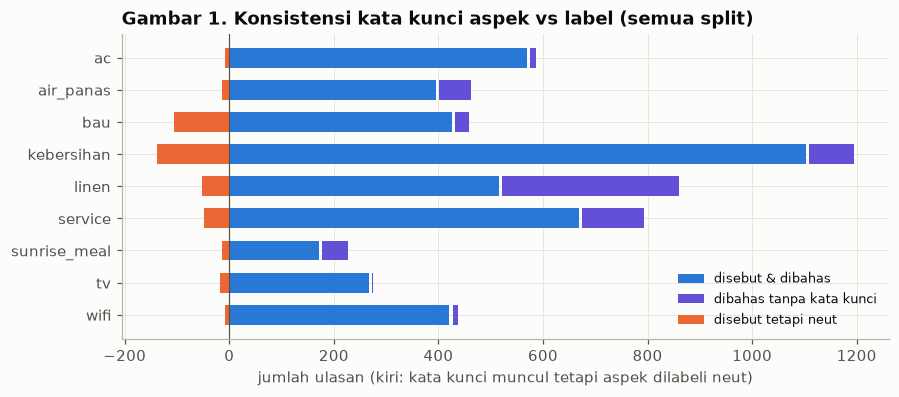

In [13]:
fig, ax = plt.subplots(figsize=(9, 3.6))
order = cons.index[::-1]
ax.barh(order, cons.loc[order, "kata kunci & dibahas"], color=C_POS, height=0.62, label="disebut & dibahas")
ax.barh(order, cons.loc[order, "dibahas tanpa kata kunci"], left=cons.loc[order, "kata kunci & dibahas"] + 6,
        color=C_NP, height=0.62, label="dibahas tanpa kata kunci")
ax.barh(order, -cons.loc[order, "disebut tetapi neut"], color=C_NEG, height=0.62, label="disebut tetapi neut")
ax.axvline(0, color=INK_2, lw=0.8)
ax.set_xlabel("jumlah ulasan (kiri: kata kunci muncul tetapi aspek dilabeli neut)")
ax.set_title("Gambar 1. Konsistensi kata kunci aspek vs label (semua split)")
ax.legend(loc="lower right", fontsize=8.5)
save_fig(fig, "01_konsistensi_label")
plt.show()

In [14]:
def show_examples(mask, aspect, n=4):
    for _, r in ALL_RAW[mask].head(n).iterrows():
        tup = [(a, r[a]) for a in ASPECTS if r[a] != "neut"]
        print(f"  [{r.split}] {r.review[:140]}\n        label: {tup}")


print("Contoh 'wifi disebut tetapi neut':")
show_examples(low.str.contains(KEYWORDS["wifi"]) & (ALL_RAW.wifi == "neut") & low.str.contains("lemot|lambat|mati|jelek|bagus|kencang|lancar"), "wifi")
print("\nContoh 'linen dibahas tanpa kata kunci linen':")
show_examples((ALL_RAW.linen != "neut") & ~low.str.contains(KEYWORDS["linen"]), "linen")

Contoh 'wifi disebut tetapi neut':
  [train] Hotel kurang maintenance, sprei tidak di ganti jadi nya bau. Wifi lemot. Kamar rata2 bau rokok padahal saya minta no smoking room. Makanan l
        label: [('bau', 'neg'), ('linen', 'neg'), ('sunrise_meal', 'pos')]
  [train] Menginap di kamar 611... Gedung hotel yg sangat bagus, resepsionis yg ramah, di dalam kamar yg bersih. Handuk hanya disediakan 2 yg besar. A
        label: [('ac', 'neg'), ('kebersihan', 'pos'), ('linen', 'neg'), ('service', 'pos')]
  [valid] tempat oke nyaman ,bagus semuanya , cuma pelayannya kurang, minta password wifi ga di kasih .alasan 
        label: [('service', 'neg')]

Contoh 'linen dibahas tanpa kata kunci linen':
  [train] ruangan kurang bersih, ada puntung rokok di dalam kamar, plastik shower di ksmar mandi mulai menghitam, conplimentary item expired 
        label: [('kebersihan', 'neg'), ('linen', 'neg')]
  [train] kamar kotor... tidak ada perlengkapan snack dan mandi dari airy
        label: [('kebersihan

In [15]:
# Apa isi aspek linen yang tidak disebut kata kuncinya? Kata paling sering pada ulasan tersebut.
mask = (ALL_RAW.linen != "neut") & ~low.str.contains(KEYWORDS["linen"])
base = Counter(w for t in low for w in set(re.findall(r"[a-z]+", t)))
sub = Counter(w for t in low[mask] for w in set(re.findall(r"[a-z]+", t)))
lift = {w: (c / mask.sum()) / (base[w] / len(low)) for w, c in sub.items() if c >= 15}
print(f"{mask.sum()} ulasan. Kata dengan lift tertinggi (muncul >= 15x):")
print(sorted(lift, key=lift.get, reverse=True)[:20])

338 ulasan. Kata dengan lift tertinggi (muncul >= 15x):
['snack', 'cemilan', 'minum', 'sabun', 'perlengkapan', 'keset', 'peralatan', 'dpt', 'sampah', 'dapat', 'tersedia', 'lengkap', 'airy', 'lain', 'ada', 'd', 'fasilitas', 'in', 'gak', 'tempat']


Aspek `linen` didefinisikan jauh lebih luas daripada namanya. Sebanyak 39,6% ulasan berlabel `linen` tidak menyebut seprai, handuk, bantal, atau kasur. Kata yang paling khas pada ulasan tersebut adalah *snack*, *cemilan*, *minum*, *sabun*, dan *perlengkapan*, misalnya "Tidak ada sabun maupun snack dari airy room" yang berlabel `linen-neg`. Dalam taksonomi Airy, `linen` mencakup seluruh perlengkapan kamar, sehingga model harus mempelajari arti aspek dari data. Aspek `sunrise_meal` (22,2%) dan `service` (15,0%) juga sering dibahas tanpa kata kuncinya, sedangkan `ac`, `tv`, dan `wifi` hampir selalu menyebut kata kuncinya.

Sebagian ulasan yang menyebut kata kunci tetapi berlabel `neut` kemungkinan merupakan label noise, misalnya "Wifi lemot" pada ulasan yang aspek wifinya berlabel `neut`. Label noise tidak dikoreksi karena tidak ada anotasi ulang yang independen dan label test harus tetap sebanding dengan literatur. Ulasan yang mencurigakan ditandai untuk analisis kesalahan model.

### 4.6 Kebisingan teks

Sel berikut menghitung proporsi ulasan yang mengandung ciri teks informal, beserta beberapa contohnya.

In [16]:
r = ALL_RAW.review
EMOJI_RE = r"[\U0001F300-\U0001FAFF☀-➿⭐]"
noise = {
    "mengandung huruf kapital": r.str.contains(r"[A-Z]"),
    "SELURUHNYA KAPITAL (>= 3 kata)": r.map(lambda t: t.isupper() and len(t.split()) >= 3),
    "emoji": r.str.contains(EMOJI_RE),
    "elongasi (huruf berulang >= 3)": r.str.contains(r"([a-zA-Z])\1\1"),
    "tanda baca berulang (!!, ??, ...)": r.str.contains(r"[!?.]{2,}"),
    "reduplikasi dengan angka (mati2)": r.str.contains(r"[a-zA-Z]{2,}2\b"),
    "singkatan umum (yg, tdk, gak, bgt, dgn)": r.str.lower().str.contains(r"\b(?:yg|tdk|gak|ga|gk|bgt|dgn|utk|krn)\b"),
    "negasi (tidak/gak/kurang/belum/...)": r.str.lower().str.contains(r"\b(?:tidak|tdk|gak|ga|gk|nggak|enggak|kurang|belum|bukan)\b"),
    "kata kontras (tapi/namun/...)": r.str.lower().str.contains(r"\b(?:tapi|tp|tetapi|namun|cuma|cuman|sayang)\b"),
    "campur kode Inggris": r.str.lower().str.contains(r"\b(?:room|staff|good|clean|nice|overall|bad|recommended|breakfast|the)\b"),
    "angka": r.str.contains(r"\d"),
}
noise_tab = pd.DataFrame({"jumlah ulasan": {k: int(v.sum()) for k, v in noise.items()},
                          "% ulasan": {k: round(100 * v.mean(), 1) for k, v in noise.items()}})
noise_tab.sort_values("% ulasan", ascending=False)

,jumlah ulasan,% ulasan
negasi (tidak/gak/kurang/belum/...),2009,70.4
mengandung huruf kapital,1504,52.7
kata kontras (tapi/namun/...),917,32.1
"singkatan umum (yg, tdk, gak, bgt, dgn)",912,32.0
"tanda baca berulang (!!, ??, ...)",594,20.8
angka,552,19.3
campur kode Inggris,328,11.5
reduplikasi dengan angka (mati2),180,6.3
emoji,60,2.1
elongasi (huruf berulang >= 3),48,1.7


In [17]:
for k in ["emoji", "elongasi (huruf berulang >= 3)", "reduplikasi dengan angka (mati2)", "campur kode Inggris"]:
    print(f"{k}:")
    for t in r[noise[k]].head(3):
        print("   ", t[:130])

emoji:
    Untuk nginap yg kemaren tempat tidur kurang bersih.. 🙏🏻
    Pelayanannya baik...tapi snack nya koq ngga ada lagi ya...kemudian bantalnya bau apek..itu aja masukannya 😁😉
    Kamar bersih. Walaupun ada sesuatu di kloset. 😬 Yg jaga sedikit banget senyumnya. Tapi nyamaaan banget kamarnya. 
elongasi (huruf berulang >= 3):
    Saya pesan yg twin bedroom. Di kasih yg single. Ada, 2 air mineral. Tapi biasanya ada Snack, tadi gak ada. Soalnya sebelumnya saya
    Wifi nya jeleeeeeeeek
    Kamar bersih. Walaupun ada sesuatu di kloset. 😬 Yg jaga sedikit banget senyumnya. Tapi nyamaaan banget kamarnya. 
reduplikasi dengan angka (mati2):
    Tempatnya si strategis, bnyak yg jual makanan di sekitarnya. Tapi Kamarnya sempit, kamar mandi bau, kran air berkarat semua, air t
    tvnya mati2
    tempatnya strategis.  deket ke mana2.  luas tapi agak jorok
campur kode Inggris:
    sangat mengecewakan... hotel bad image, kebersihan kurang, berisik
    Tempat tidur sangat keras, bantal besar dan ke

Teks HoASA adalah bahasa Indonesia informal. Sebanyak 52,7% ulasan memakai huruf kapital secara tidak konsisten, 32,0% memuat singkatan seperti *yg* dan *tdk*, dan 11,5% bercampur kode dengan bahasa Inggris. Negasi muncul pada 70,4% ulasan dan kata kontras seperti *tapi* pada 32,1% ulasan. Kedua jenis kata ini menentukan polaritas, sehingga preprocessing tidak boleh menghapusnya (bagian 7.6).

## 5. Analisis Data Eksploratif

### 5.1 Distribusi label per aspek

Gambar 2 menunjukkan jumlah ulasan train yang membahas setiap aspek beserta polaritasnya. Tabel di bawahnya memuat angka yang sama, ditambah persentase ulasan yang membahas aspek dan rasio negatif terhadap positif.

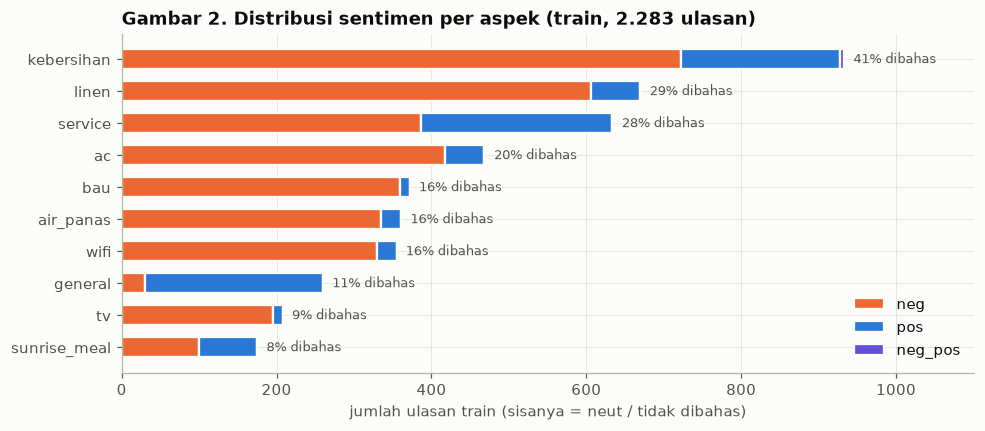

,neg,neut,pos,neg_pos,% dibahas,rasio neg:pos
kebersihan,722,1350,205,6,40.9,3.5
linen,606,1613,63,1,29.3,9.6
service,386,1649,247,1,27.8,1.6
ac,417,1814,51,1,20.5,8.2
bau,360,1911,12,0,16.3,30.0
air_panas,335,1922,26,0,15.8,12.9
wifi,330,1928,25,0,15.5,13.2
general,30,2023,230,0,11.4,0.1
tv,195,2075,13,0,9.1,15.0
sunrise_meal,100,2108,75,0,7.7,1.3


In [18]:
TR = RAW["train"]
dist = pd.DataFrame({a: TR[a].value_counts() for a in ASPECTS}).T.reindex(columns=CLASSES).fillna(0).astype(int)
dist["% dibahas"] = (100 * (1 - dist["neut"] / len(TR))).round(1)
dist["rasio neg:pos"] = (dist["neg"] / dist["pos"]).round(1)
dist = dist.sort_values("% dibahas", ascending=False)

fig, ax = plt.subplots(figsize=(10, 4))
order = dist.index[::-1]
left = np.zeros(len(order))
for c in ["neg", "pos", "neg_pos"]:
    ax.barh(order, dist.loc[order, c], left=left, color=COLOR[c], height=0.62, label=c, edgecolor=SURFACE, linewidth=1.5)
    left += dist.loc[order, c].values
for i, a in enumerate(order):
    ax.text(left[i] + 12, i, f"{dist.loc[a, '% dibahas']:.0f}% dibahas", va="center", fontsize=8.5, color=INK_2)
ax.set_xlabel("jumlah ulasan train (sisanya = neut / tidak dibahas)")
ax.set_title("Gambar 2. Distribusi sentimen per aspek (train, 2.283 ulasan)")
ax.legend(loc="lower right")
ax.set_xlim(0, left.max() * 1.18)
save_fig(fig, "02_distribusi_label")
plt.show()
dist

### 5.2 Ketidakseimbangan kelas

Ketidakseimbangan dihitung pada tingkat sel (ulasan × aspek), per aspek, dan pada jumlah sel positif di valid dan test.

In [19]:
cells = TR[ASPECTS].values.ravel()
tot = pd.Series(cells).value_counts().reindex(CLASSES)
print("Distribusi semua sel train (ulasan x aspek):")
print((tot / tot.sum() * 100).round(2).astype(str).add("%").to_string())
print(f"\nRasio neut : neg : pos = {tot['neut'] / tot['pos']:.1f} : {tot['neg'] / tot['pos']:.1f} : 1")
print("\nAspek paling timpang (rasio neg:pos):", dist["rasio neg:pos"].sort_values(ascending=False).head(4).to_dict())
print("Aspek dengan arah terbalik (pos > neg):", dist.index[dist["pos"] > dist["neg"]].tolist())
print("\nJumlah sel pos di VALID dan TEST per aspek (dasar metrik per aspek):")
pd.DataFrame({s: (RAW[s][ASPECTS] == "pos").sum() for s in ["valid", "test"]}).T

Distribusi semua sel train (ulasan x aspek):
neg        15.25%
neut       80.57%
pos         4.15%
neg_pos     0.04%

Rasio neut : neg : pos = 19.4 : 3.7 : 1

Aspek paling timpang (rasio neg:pos): {'bau': 30.0, 'tv': 15.0, 'wifi': 13.2, 'air_panas': 12.9}
Aspek dengan arah terbalik (pos > neg): ['general']

Jumlah sel pos di VALID dan TEST per aspek (dasar metrik per aspek):


,ac,air_panas,bau,general,kebersihan,linen,service,sunrise_meal,tv,wifi
valid,7,7,1,30,24,13,32,9,3,2
test,8,3,1,38,32,9,36,8,3,1


Ketidakseimbangan terjadi pada tiga tingkat. Pertama, 80,6% sel berlabel `neut`. Kedua, ulasan didominasi keluhan dengan rasio negatif terhadap positif 3,7 : 1, dan rasio ini mencapai 30 : 1 pada `bau`. Ketiga, `kebersihan` dibahas pada 40,9% ulasan, sedangkan `tv` dan `sunrise_meal` kurang dari 10%. Hanya `general` yang lebih banyak berlabel positif, karena umumnya berisi kesan umum seperti "overall oke".

Di test, `bau` dan `wifi` masing-masing hanya memiliki 1 sel positif. F1 kelas `pos` per aspek akan sangat berfluktuasi, sehingga metrik utama harus menggabungkan seluruh sel, seperti F1 IndoNLU dan F1 pasangan.

### 5.3 Konsistensi distribusi antar split

Proporsi `neg` dan `pos` per aspek dibandingkan antar split, lalu diuji dengan uji chi-kuadrat homogenitas.

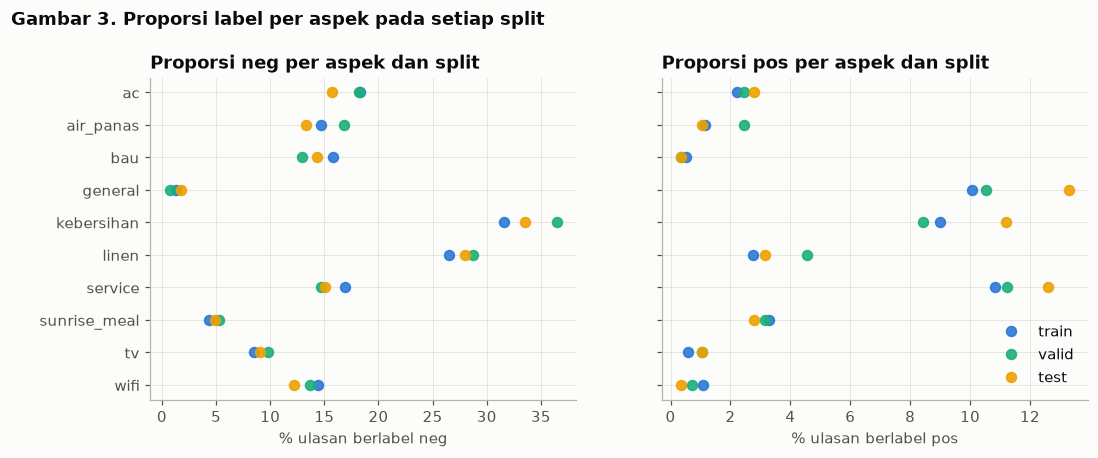

Uji chi-kuadrat homogenitas label antar split (p-value per aspek):
{'ac': 0.835, 'air_panas': 0.254, 'bau': 0.718, 'general': 0.387, 'kebersihan': 0.339, 'linen': 0.405, 'service': 0.73, 'sunrise_meal': 0.946, 'tv': 0.695, 'wifi': 0.573}


In [20]:
from scipy.stats import chi2_contingency

prop = {}
for s, d in RAW.items():
    for a in ASPECTS:
        for c in ["neg", "pos"]:
            prop[(a, c, s)] = (d[a] == c).mean() * 100
prop = pd.Series(prop).unstack()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, c in zip(axes, ["neg", "pos"]):
    sub = prop.xs(c, level=1).reindex(ASPECTS[::-1])
    for s in SPLITS:
        ax.plot(sub[s], range(len(sub)), "o", ms=6.5, color=SPLIT_COLOR[s], label=s, alpha=0.9)
    ax.set_yticks(range(len(sub)), sub.index)
    ax.set_xlabel(f"% ulasan berlabel {c}")
    ax.set_title(f"Proporsi {c} per aspek dan split")
axes[1].legend(loc="lower right")
fig.suptitle("Gambar 3. Proporsi label per aspek pada setiap split", x=0.01, y=1.04, ha="left", fontweight="bold")
save_fig(fig, "03_distribusi_antar_split")
plt.show()

pv = {}
for a in ASPECTS:
    tab = pd.crosstab(ALL_RAW[a].replace("neg_pos", "neg"), ALL_RAW.split)
    pv[a] = chi2_contingency(tab)[1]
print("Uji chi-kuadrat homogenitas label antar split (p-value per aspek):")
print(pd.Series(pv).round(3).to_dict())

Proporsi label pada ketiga split mirip. Nilai p terkecil adalah 0,254 (`air_panas`), sehingga tidak ada aspek yang berbeda signifikan, bahkan tanpa koreksi Bonferroni untuk sepuluh uji. Split resmi IndoNLU dipakai apa adanya agar hasil dapat dibandingkan dengan literatur.

### 5.4 Jumlah aspek per ulasan dan polaritas campuran

Untuk setiap ulasan train dihitung jumlah aspek yang dibahas dan komposisi polaritasnya.

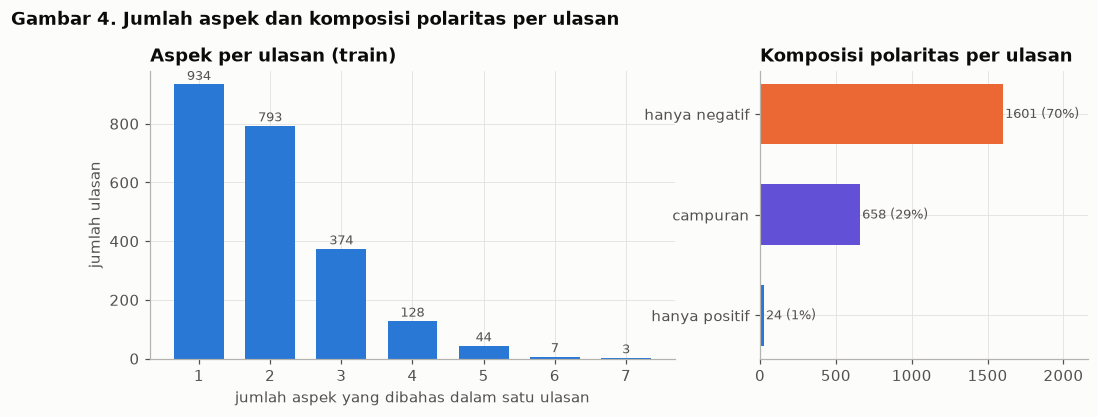

Rata-rata aspek per ulasan: 1.94 | ulasan dengan >= 2 aspek: 59.1%


In [21]:
n_asp = (TR[ASPECTS] != "neut").sum(axis=1)
has_neg = (TR[ASPECTS].isin(["neg", "neg_pos"])).any(axis=1)
has_pos = (TR[ASPECTS].isin(["pos", "neg_pos"])).any(axis=1)
kind = np.select([has_neg & has_pos, has_neg], ["campuran", "hanya negatif"], "hanya positif")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.4), gridspec_kw={"width_ratios": [1.6, 1]})
vc = n_asp.value_counts().sort_index()
axes[0].bar(vc.index, vc.values, color=C_POS, width=0.7)
for x, v in vc.items():
    axes[0].text(x, v + 15, f"{v}", ha="center", fontsize=8.5, color=INK_2)
axes[0].set_xlabel("jumlah aspek yang dibahas dalam satu ulasan")
axes[0].set_ylabel("jumlah ulasan")
axes[0].set_title("Aspek per ulasan (train)")
kc = pd.Series(kind).value_counts().reindex(["hanya negatif", "campuran", "hanya positif"])
axes[1].barh(kc.index[::-1], kc.values[::-1], color=[C_POS, C_NP, C_NEG], height=0.6)
for i, v in enumerate(kc.values[::-1]):
    axes[1].text(v + 15, i, f"{v} ({100 * v / len(TR):.0f}%)", va="center", fontsize=8.5, color=INK_2)
axes[1].set_xlim(0, kc.max() * 1.35)
axes[1].set_title("Komposisi polaritas per ulasan")
fig.suptitle("Gambar 4. Jumlah aspek dan komposisi polaritas per ulasan", x=0.01, y=1.04, ha="left", fontweight="bold")
save_fig(fig, "04_aspek_per_ulasan")
plt.show()
print(f"Rata-rata aspek per ulasan: {n_asp.mean():.2f} | ulasan dengan >= 2 aspek: {(n_asp >= 2).mean():.1%}")

Rata-rata satu ulasan membahas 1,94 aspek, dan 59,1% ulasan membahas dua aspek atau lebih. Sebanyak 29% ulasan berpolaritas campuran, misalnya "kamar bersih tapi AC tidak dingin", sehingga representasi model harus dapat berbeda untuk setiap aspek.

### 5.5 Ko-okurensi aspek

Lift mengukur seberapa sering dua aspek dibahas bersama dibandingkan dengan perkiraan bila keduanya independen. Nilai di atas 1 berarti keduanya lebih sering muncul bersama.

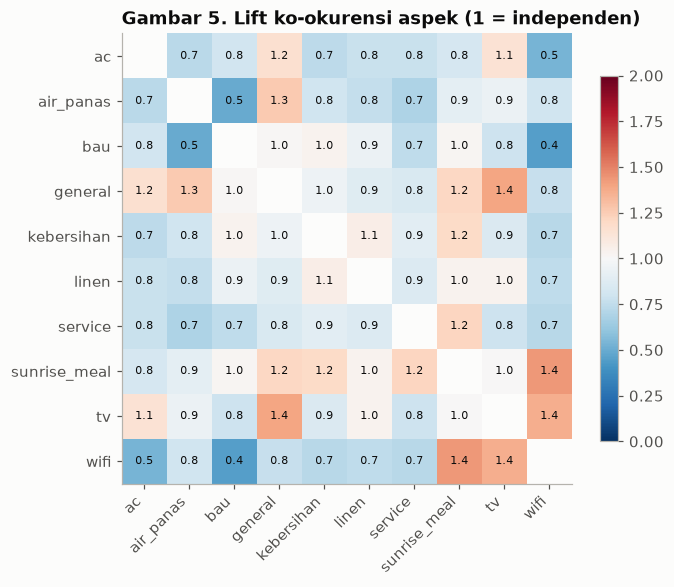

In [22]:
B = (TR[ASPECTS] != "neut").astype(int)
co = B.T @ B
p_a = B.mean()
lift = (co / len(TR)) / np.outer(p_a, p_a)
lift = lift.mask(np.eye(len(ASPECTS), dtype=bool))

fig, ax = plt.subplots(figsize=(6.6, 5.4))
im = ax.imshow(lift.values, cmap="RdBu_r", vmin=0, vmax=2)
ax.set_xticks(range(10), ASPECTS, rotation=45, ha="right")
ax.set_yticks(range(10), ASPECTS)
for i in range(10):
    for j in range(10):
        if i != j:
            ax.text(j, i, f"{lift.values[i, j]:.1f}", ha="center", va="center", fontsize=7.5,
                    color="white" if abs(lift.values[i, j] - 1) > 0.6 else INK)
ax.grid(False)
ax.set_title("Gambar 5. Lift ko-okurensi aspek (1 = independen)")
fig.colorbar(im, ax=ax, shrink=0.8)
save_fig(fig, "05_kookurensi_aspek")
plt.show()

Sekitar dua pertiga pasangan aspek memiliki lift di bawah 1, karena banyak ulasan pendek hanya berisi satu keluhan. Pasangan yang paling sering muncul bersama adalah `wifi`–`sunrise_meal`, `general`–`tv`, dan `tv`–`wifi` (lift sekitar 1,4), sedangkan `bau`–`wifi` paling jarang (0,45). Karena aspek saling bergantung, kesepuluh aspek diprediksi oleh satu encoder bersama.

### 5.6 Panjang ulasan

Panjang ulasan dihitung dalam kata untuk setiap split, lalu dibandingkan dengan jumlah aspek yang dibahas.

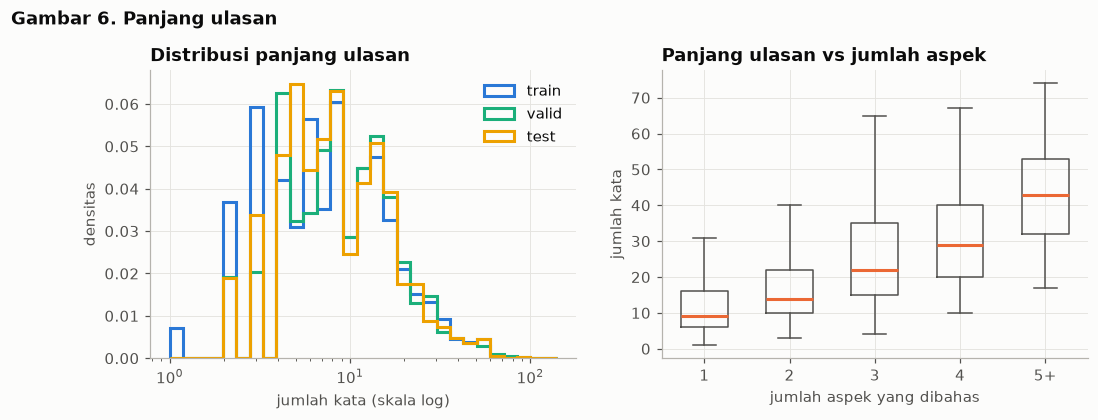

        count  mean   std  min   50%   95%   99%    max
split                                                  
test    286.0  17.9  14.1  2.0  13.0  50.2  60.1   99.0
train  2283.0  18.5  14.4  1.0  14.0  51.0  60.0  140.0
valid   285.0  19.0  15.8  2.0  14.0  50.4  76.2  133.0

Korelasi Spearman panjang vs jumlah aspek: rho = 0.52 (p = 4.8e-198)


In [23]:
ALL_RAW["n_kata"] = ALL_RAW.review.str.split().str.len()
ALL_RAW["n_aspek"] = (ALL_RAW[ASPECTS] != "neut").sum(axis=1)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.4))
bins = np.logspace(0, np.log10(ALL_RAW.n_kata.max() + 1), 30)
for s in SPLITS:
    axes[0].hist(ALL_RAW.loc[ALL_RAW.split == s, "n_kata"], bins=bins, histtype="step", lw=2, density=True,
                 color=SPLIT_COLOR[s], label=s)
axes[0].set_xscale("log")
axes[0].set_xlabel("jumlah kata (skala log)")
axes[0].set_ylabel("densitas")
axes[0].set_title("Distribusi panjang ulasan")
axes[0].legend()
grp = [ALL_RAW.loc[ALL_RAW.n_aspek.clip(upper=5) == k, "n_kata"] for k in range(1, 6)]
axes[1].boxplot(grp, positions=range(1, 6), widths=0.55, showfliers=False,
                medianprops={"color": C_NEG, "lw": 2}, boxprops={"color": INK_2}, whiskerprops={"color": INK_2}, capprops={"color": INK_2})
axes[1].set_xticks(range(1, 6), ["1", "2", "3", "4", "5+"])
axes[1].set_xlabel("jumlah aspek yang dibahas")
axes[1].set_ylabel("jumlah kata")
axes[1].set_title("Panjang ulasan vs jumlah aspek")
fig.suptitle("Gambar 6. Panjang ulasan", x=0.01, y=1.04, ha="left", fontweight="bold")
save_fig(fig, "06_panjang_ulasan")
plt.show()
from scipy.stats import spearmanr
rho = spearmanr(ALL_RAW.n_kata, ALL_RAW.n_aspek)
print(ALL_RAW.groupby("split").n_kata.describe(percentiles=[0.5, 0.95, 0.99]).round(1))
print(f"\nKorelasi Spearman panjang vs jumlah aspek: rho = {rho.statistic:.2f} (p = {rho.pvalue:.1e})")

Median panjang ulasan 14 kata dan 95% ulasan train lebih pendek dari 51 kata, tetapi distribusinya condong ke kanan hingga 140 kata. Panjang ulasan berkorelasi dengan jumlah aspek yang dibahas (Spearman ρ = 0,52), sehingga pemotongan input yang terlalu pendek akan membuang aspek pada ulasan panjang. Panjang dalam satuan subword diukur pada bagian 7.7.

### 5.7 Kosakata

Ukuran kosakata, jumlah kata yang hanya muncul sekali, dan OOV valid serta test terhadap kosakata train dihitung pada tingkat kata.

In [24]:
def words(texts):
    return [w for t in texts for w in re.findall(r"[a-z0-9]+", t.lower())]


wtr, wte = words(RAW["train"].review), words(pd.concat([RAW["valid"].review, RAW["test"].review]))
ctr = Counter(wtr)
hapax = sum(1 for c in ctr.values() if c == 1)
oov_tok = np.mean([w not in ctr for w in wte])
print(f"Token train: {len(wtr):,} | tipe kata: {len(ctr):,} | hapax (muncul 1x): {hapax:,} ({hapax / len(ctr):.0%} tipe)")
print(f"OOV valid+test terhadap kosakata train: {oov_tok:.1%} token | {np.mean([w not in ctr for w in set(wte)]):.1%} tipe")
print("30 kata terbanyak:", [w for w, _ in ctr.most_common(30)])

Token train: 42,613 | tipe kata: 4,658 | hapax (muncul 1x): 2,583 (55% tipe)
OOV valid+test terhadap kosakata train: 5.7% token | 28.2% tipe
30 kata terbanyak: ['kamar', 'tidak', 'dan', 'ada', 'di', 'kurang', 'nya', 'air', 'mandi', 'bersih', 'ac', 'yg', 'bau', 'kotor', 'tapi', 'dingin', 'nyaman', 'wifi', 'panas', 'baik', 'saya', 'yang', 'airy', 'ga', 'bagus', 'hanya', 'bisa', 'ramah', 'pelayanan', 'sangat']


Kosakata train berisi 4.658 tipe kata, dan 55% di antaranya hanya muncul sekali, umumnya varian ejaan atau salah ketik. Akibatnya, 5,7% token valid dan test tidak pernah muncul di train. Masalah ini paling berat bagi model berbasis kata, sehingga model kata pada notebook 2 memakai embedding FastText yang membentuk vektor dari n-gram karakter.

### 5.8 Kata khas per aspek dan per polaritas

Kata khas dicari dengan *log-odds ratio* berprior Dirichlet informatif (Monroe dkk., 2008) yang dinyatakan sebagai z-score. Metode ini lebih andal daripada frekuensi mentah karena memperhitungkan ketidakpastian pada kata yang jarang.

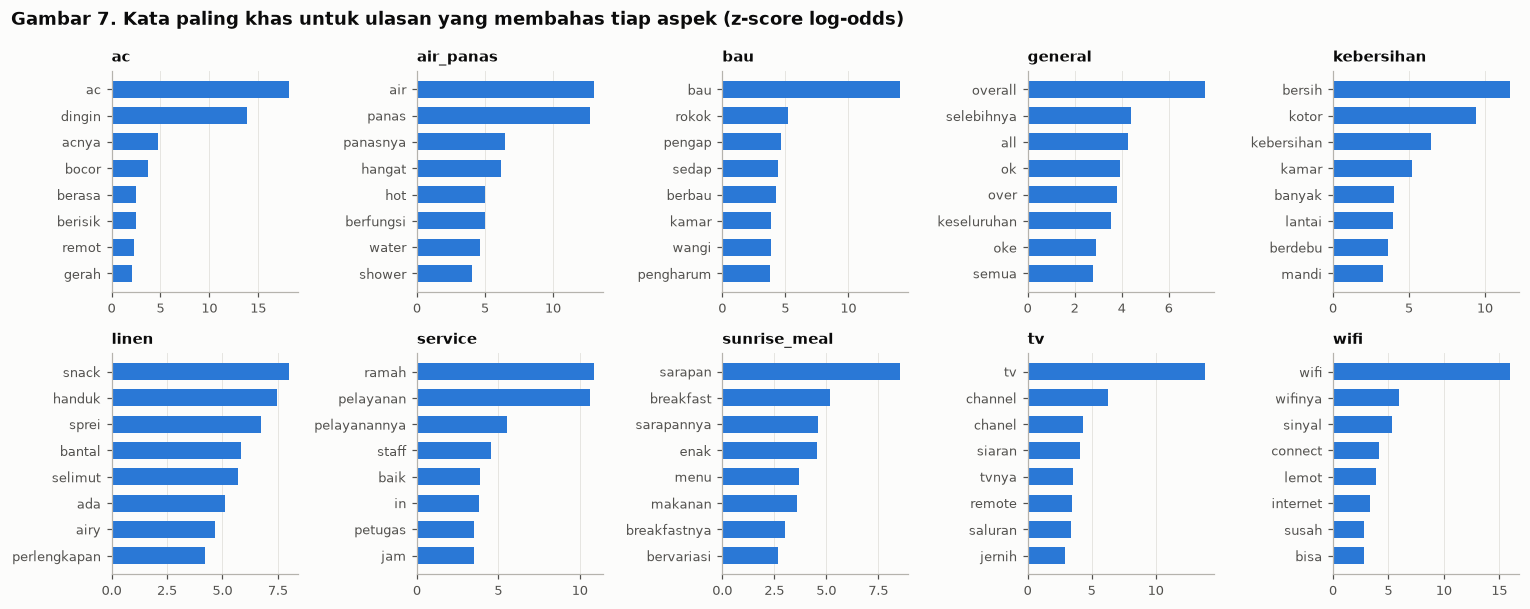

In [25]:
def log_odds(texts_a, texts_b, prior_texts, min_count=5):
    ca, cb, cp = Counter(words(texts_a)), Counter(words(texts_b)), Counter(words(prior_texts))
    na, nb, a0 = sum(ca.values()), sum(cb.values()), sum(cp.values())
    out = {}
    for w, pw in cp.items():
        if ca[w] + cb[w] < min_count:
            continue
        d = np.log((ca[w] + pw) / (na + a0 - ca[w] - pw)) - np.log((cb[w] + pw) / (nb + a0 - cb[w] - pw))
        out[w] = d / np.sqrt(1 / (ca[w] + pw) + 1 / (cb[w] + pw))
    return pd.Series(out).sort_values(ascending=False)


fig, axes = plt.subplots(2, 5, figsize=(14, 5.6))
for ax, a in zip(axes.ravel(), ASPECTS):
    m = TR[a] != "neut"
    z = log_odds(TR.review[m], TR.review[~m], TR.review).head(8)[::-1]
    ax.barh(z.index, z.values, color=C_POS, height=0.65)
    ax.set_title(a, fontsize=10)
    ax.tick_params(labelsize=8.5)
    ax.grid(axis="y", visible=False)
fig.suptitle("Gambar 7. Kata paling khas untuk ulasan yang membahas tiap aspek (z-score log-odds)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_fig(fig, "07_kata_khas_aspek")
plt.show()

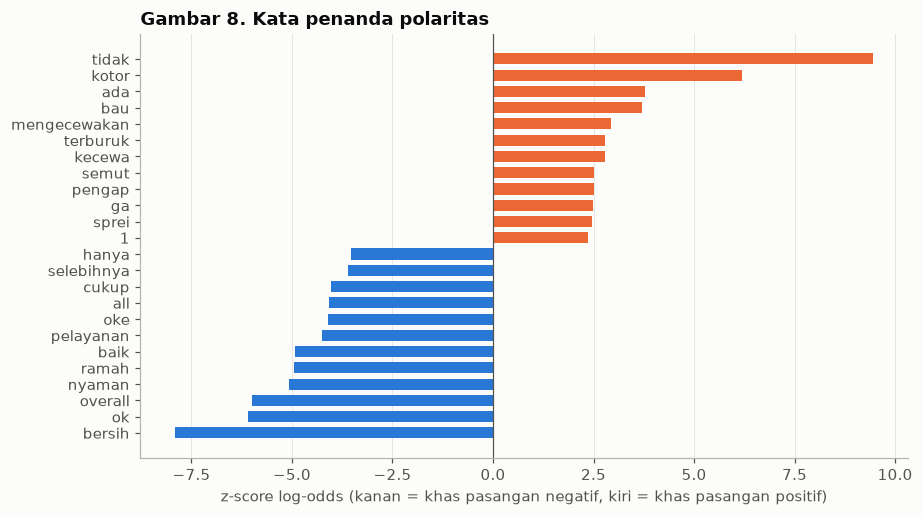

In [26]:
# Penanda polaritas di tingkat pasangan: kalimat yang memuat (aspek, neg) vs (aspek, pos)
L = to_long(TR)
neg_txt, pos_txt = L.review[L.sentiment == "neg"], L.review[L.sentiment == "pos"]
z = log_odds(neg_txt, pos_txt, TR.review)
top = pd.concat([z.head(12), z.tail(12)])
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top.index[::-1], top.values[::-1], color=[C_NEG if v > 0 else C_POS for v in top.values[::-1]], height=0.68)
ax.axvline(0, color=INK_2, lw=0.8)
ax.set_xlabel("z-score log-odds (kanan = khas pasangan negatif, kiri = khas pasangan positif)")
ax.set_title("Gambar 8. Kata penanda polaritas")
ax.grid(axis="y", visible=False)
save_fig(fig, "08_penanda_polaritas")
plt.show()

Gambar 7 menunjukkan bahwa kosakata setiap aspek sempit dan sesuai intuisi, misalnya *dingin* untuk `ac`, *lemot* untuk `wifi`, serta *apek* dan *rokok* untuk `bau`. Pada Gambar 8, penanda negatif terkuat adalah *tidak*, diikuti kata keluhan seperti *kotor*, *bau*, dan *kecewa*. Penanda positif berupa kata pujian (*bersih*, *nyaman*, *ramah*) dan penutup kesan umum (*ok*, *overall*, *selebihnya*). Karena *bersih* adalah penanda positif terkuat, frasa *tidak bersih* hanya terbaca benar bila negasi dipertahankan dan urutan kata diperhitungkan.

Gambar 8a menyajikan temuan yang sama dalam bentuk word cloud. Panel kiri menampilkan kata tersering di train, dengan kata fungsi disembunyikan khusus untuk tampilan. Panel tengah dan kanan memakai z-score log-odds dari Gambar 8 sebagai ukuran kata, karena hampir semua ulasan memuat keluhan sehingga frekuensi mentah akan didominasi kata umum seperti *kamar*.

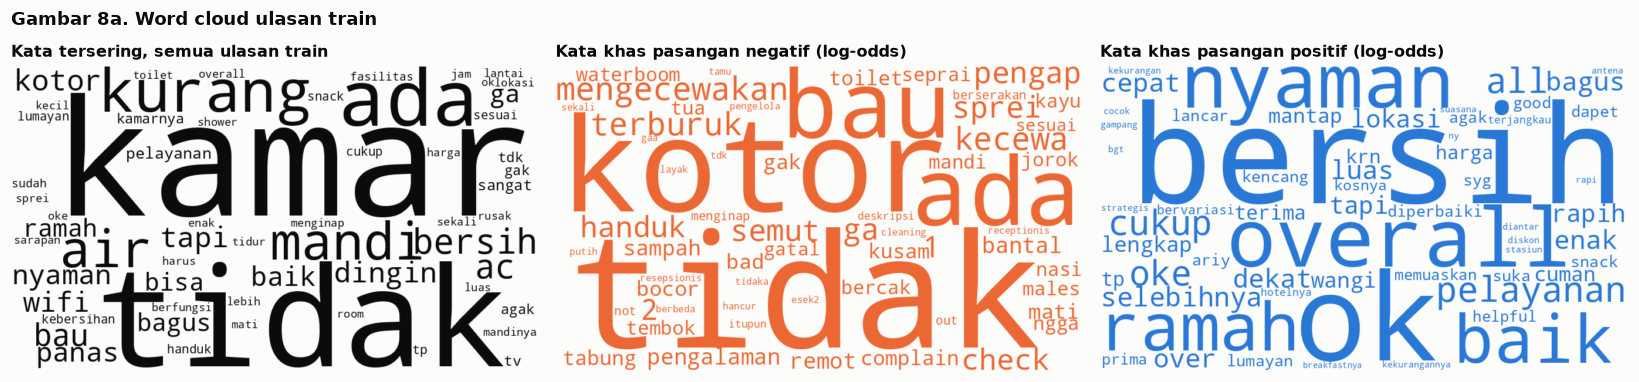

In [27]:
from wordcloud import WordCloud

SW_SHOW = P.stopwords() | {"nya", "aja", "sih", "ya", "yg", "dgn", "utk", "jg", "kalo", "klo", "hotel", "airy"}


def cloud(freq, color):
    return WordCloud(width=900, height=520, background_color=SURFACE, max_words=60, prefer_horizontal=1.0,
                     color_func=lambda *a, **k: color, random_state=SEED).generate_from_frequencies(freq)


freq_all = Counter(w for w in words(TR.review) if w not in SW_SHOW and len(w) > 1)
z_neg = {w: v for w, v in z.items() if v > 0 and w not in SW_SHOW}
z_pos = {w: -v for w, v in z.items() if v < 0 and w not in SW_SHOW}
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
for ax, (title, freq, c) in zip(axes, [("Kata tersering, semua ulasan train", freq_all, INK),
                                       ("Kata khas pasangan negatif (log-odds)", z_neg, C_NEG),
                                       ("Kata khas pasangan positif (log-odds)", z_pos, C_POS)]):
    ax.imshow(cloud(freq, c), interpolation="bilinear")
    ax.set_title(title, fontsize=10.5)
    ax.axis("off")
fig.suptitle("Gambar 8a. Word cloud ulasan train", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_fig(fig, "08a_word_cloud")
plt.show()

Kata tersering adalah objek aspek (*kamar*, *air*, *mandi*, *ac*) dan kata penilaian (*kotor*, *bersih*, *dingin*). Kata *tidak* menjadi kata terbesar pada panel negatif. Keluhan di HoASA lebih sering berupa negasi atas kata positif (*tidak dingin*, *kurang bersih*) daripada kata negatif langsung, sehingga model yang membuang negasi atau mengabaikan urutan kata akan membalik polaritas.

### 5.9 Jarak kata opini dari kata aspek

Bila opini hampir selalu menempel pada kata aspeknya (*ac tidak dingin*), detektor frasa pendek seperti n-gram atau CNN sudah memadai. Bila opini sering berada jauh, model perlu membaca konteks yang lebih panjang. Untuk setiap aspek yang dibahas dan disebut kata kuncinya, dihitung rentang ke kata opini terdekat, yaitu jarak dalam kata ditambah satu. Leksikon opini sengaja dibuat kecil, berisi negasi dan kata penilaian yang umum pada ulasan hotel.

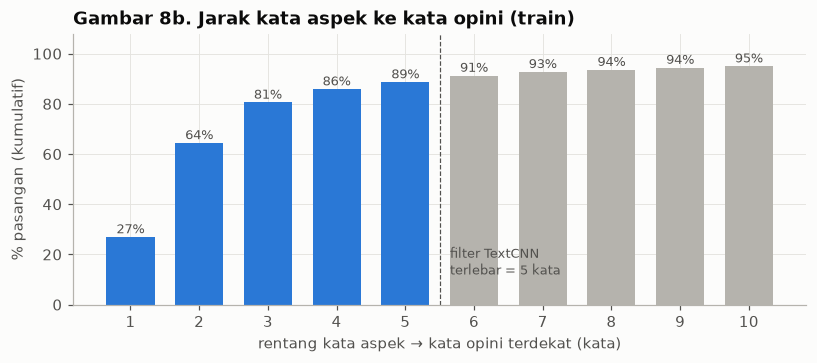

3,653 pasangan (aspek dibahas & kata kuncinya disebut) | tanpa kata opini sama sekali: 2.8%
% rentang <= 5 kata per aspek: {'ac': 91, 'air_panas': 95, 'bau': 95, 'kebersihan': 93, 'linen': 80, 'service': 88, 'sunrise_meal': 81, 'tv': 78, 'wifi': 84}


In [28]:
ASPEK_TOKEN = {   # kata kunci aspek di tingkat token (bagian 4.5), termasuk bentuk ber-klitik
    "ac": r"ac|acnya|aircon|pendingin\w*", "air_panas": r"air|airnya|heater|shower\w*",
    "bau": r"bau\w*|berbau|apek|pesing|harum|wangi|aroma",
    "kebersihan": r"bersih\w*|kebersihan\w*|kotor\w*|debu|berdebu|jorok|kumuh|kecoa|semut|nyamuk",
    "linen": r"seprai\w*|sprei\w*|sprai|handuk\w*|selimut\w*|bantal\w*|linen|kasur\w*|snack\w*|sabun\w*|perlengkapan",
    "service": r"pelayan\w*|layanan\w*|staf\w*|staff\w*|resepsionis|receptionist|petugas\w*|penjaga\w*|karyawan\w*|service",
    "sunrise_meal": r"sarapan\w*|breakfast\w*", "tv": r"tv\w*|televisi|tivi|channel\w*", "wifi": r"wifi\w*|internet\w*|sinyal\w*",
}
OPINI = set(("tidak tdk gak ga gk nggak enggak kurang belum bukan bersih kotor jorok berdebu bau wangi harum apek pengap "
             "dingin panas gerah hangat mati rusak bocor berisik lemot lambat kencang lancar cepat susah jelek buruk bagus "
             "baik enak nyaman ramah jutek sopan mantap oke ok kecewa mengecewakan memuaskan puas lengkap jernih berfungsi "
             "recommended parah").split())

rows = []
for _, r in TR.iterrows():
    toks = re.findall(r"[a-z0-9]+", r.review.lower())
    pos_op = [i for i, w in enumerate(toks) if w in OPINI]
    for a, pat in ASPEK_TOKEN.items():
        if r[a] == "neut":
            continue
        pos_kw = [i for i, w in enumerate(toks) if re.fullmatch(pat, w)]
        if pos_kw:
            d = min((abs(i - j) for i in pos_kw for j in pos_op), default=np.inf)
            rows.append({"aspek": a, "rentang": d + 1})
JARAK = pd.DataFrame(rows)
cum = pd.Series({k: (JARAK.rentang <= k).mean() * 100 for k in range(1, 11)})

fig, ax = plt.subplots(figsize=(8.6, 3.2))
ax.bar(cum.index, cum.values, color=[C_POS if k <= 5 else C_NEUT for k in cum.index], width=0.7)
for k, v in cum.items():
    ax.text(k, v + 1.5, f"{v:.0f}%", ha="center", fontsize=8.5, color=INK_2)
ax.axvline(5.5, color=INK_2, lw=0.8, ls="--")
ax.text(5.65, 12, "filter TextCNN\nterlebar = 5 kata", fontsize=8.5, color=INK_2)
ax.set_xticks(cum.index)
ax.set_xlabel("rentang kata aspek → kata opini terdekat (kata)")
ax.set_ylabel("% pasangan (kumulatif)")
ax.set_ylim(0, 108)
ax.set_title("Gambar 8b. Jarak kata aspek ke kata opini (train)")
save_fig(fig, "08b_jarak_aspek_opini")
plt.show()
print(f"{len(JARAK):,} pasangan (aspek dibahas & kata kuncinya disebut) | tanpa kata opini sama sekali: {np.isinf(JARAK.rentang).mean():.1%}")
print("% rentang <= 5 kata per aspek:", JARAK.groupby("aspek").rentang.apply(lambda s: round(100 * (s <= 5).mean())).to_dict())

Sebanyak 64% kata opini berada dalam rentang 2 kata dari kata aspeknya dan 89% dalam rentang 5 kata. Temuan ini menjadi dasar pemakaian n-gram kata 1–2 dan n-gram karakter pada TF-IDF, serta filter selebar 2–5 kata pada TextCNN; Kim (2014) memakai lebar 3–5, dan lebar 2 ditambahkan karena rentang 2 paling umum. Sekitar 11% opini berjarak lebih dari 5 kata. Bersama aspek yang dibahas tanpa kata kunci dan aspek `general`, bagian data ini memerlukan model yang membaca seluruh konteks, seperti BiLSTM dengan attention dan Transformer. Leksikon opininya tidak lengkap, sehingga angka ini merupakan perkiraan.

### 5.10 Ringkasan temuan EDA dan keputusan desain

Tabel berikut menghubungkan temuan pada bagian 3–5 dengan keputusan pada preprocessing (bagian 7), pemodelan (notebook 2), dan evaluasi. Kode model (Ref, A–G) mengikuti tabel pada awal notebook 2.

| Temuan | Angka | Bagian | Keputusan |
|---|---|---|---|
| `neut` berarti tidak dibahas dan mendominasi sel | 80,6% sel | 3.3, 5.1 | macro-F1 IndoNLU, F1 pasangan, dan exact match; bukan akurasi |
| `neg_pos` hanya ada di train | 9 sel | 3.4, 4.4 | latih 4 kelas, gabungkan `neg_pos` ke `neg` setelah softmax |
| `pos` sangat langka di test | 1 sel pada `bau` dan `wifi` | 5.2 | 3 seed dan uji bootstrap berpasangan |
| banyak aspek per ulasan, polaritas campuran | 59% ≥ 2 aspek, 29% campuran | 5.4 | representasi per aspek: attention (B) dan AspAttn-Desc |
| aspek saling bergantung | lift 0,45–1,43 | 5.5 | satu encoder bersama untuk 10 aspek |
| opini umumnya dekat dengan kata aspek | 89% dalam 5 kata | 5.9 | n-gram 1–2 dan karakter 2–5 pada TF-IDF (Ref); filter 2–5 pada TextCNN (C) |
| sebagian opini jauh atau aspek implisit | 11% > 5 kata; 40% `linen` tanpa kata kunci | 4.5, 5.9 | model kontekstual (B, D–G) dan deskripsi aspek dari data |
| ulasan pendek dengan ekor panjang | median 14 kata; p99 84–98 subword | 5.6, 7.7 | panjang maksimum 128 subword |
| kosakata berekor panjang | 55% tipe muncul sekali; OOV 5,7% | 5.7 | embedding FastText dan tokenizer subword |
| negasi dan kontras menentukan polaritas | 70,4% dan 32,1% ulasan | 4.6, 5.8 | stopword generik tidak dipakai; negasi diseragamkan |
| teks informal dan campur kode | campur kode 11,5% ulasan | 4.6 | emoji diubah menjadi kata; XLM-R (E, G) ikut diuji |
| definisi aspek lebih luas dari namanya | `linen` = perlengkapan kamar | 4.5 | deskripsi aspek ditambang dari data train (notebook 3) |

## 6. Penanganan Masalah Data

Tabel berikut merangkum masalah yang ditemukan dan cara penanganannya. Sel kode setelahnya menerapkan penanganan nomor 1 sampai 4.

| No. | Masalah (bagian) | Penanganan |
|---|---|---|
| 1 | Duplikat di dalam train (4.2) | Duplikat dihapus, satu salinan disimpan |
| 2 | Teks train identik dengan valid/test (4.2) | Salinan di train dihapus; valid dan test tidak diubah |
| 3 | `neg_pos` hanya 9 sel dan tidak ada di valid/test (3.4, 4.4) | Kolom `<aspek>_orig` (4 kelas) untuk pelatihan; kolom `<aspek>` dengan `neg_pos` → `neg` (3 kelas, sesuai panduan anotasi) untuk evaluasi. Saat prediksi, probabilitas `neg_pos` digabung ke `neg` |
| 4 | Label noise (4.5) | Tidak dikoreksi; ulasan yang mencurigakan ditandai di kolom `suspect` |
| 5 | Definisi aspek tidak sesuai nama (4.5) | Dicatat; model mempelajari arti aspek dari data |
| 6 | Ketidakseimbangan berlapis (5.2) | Data tidak diubah; macro-F1 memberi bobot setara pada ketiga kelas; pembobotan kelas tidak dipakai, mengikuti IndoNLU |
| 7 | Teks informal, singkatan, emoji (4.6) | Preprocessing bertingkat, dipilih per jenis model (bagian 7) |
| 8 | Ulasan panjang (5.6) | Panjang maksimum dipilih dari distribusi subword (bagian 7.7) |

In [29]:
DATA = {s: d.copy() for s, d in RAW.items()}
for s, d in DATA.items():
    d["key"] = d.review.map(dup_key)
n0 = len(DATA["train"])

# (1) duplikat di dalam train
DATA["train"] = DATA["train"].drop_duplicates("key", keep="first")
n1 = len(DATA["train"])
# (2) kebocoran: teks train yang identik dengan valid/test
eval_keys = set(DATA["valid"].key) | set(DATA["test"].key)
leaked = DATA["train"][DATA["train"].key.isin(eval_keys)]
DATA["train"] = DATA["train"][~DATA["train"].key.isin(eval_keys)]
print(f"train: {n0} -> {n1} (hapus {n0 - n1} duplikat) -> {len(DATA['train'])} (hapus {len(leaked)} yang bocor ke valid/test)")
print("Teks bocor yang dihapus:", leaked.review.tolist())

# (3) label 3 kelas (neg_pos -> neg) untuk evaluasi; label asli 4 kelas disimpan di kolom <aspek>_orig untuk pelatihan
for s, d in DATA.items():
    for a in ASPECTS:
        d[f"{a}_orig"] = d[a]
        d[a] = d[a].replace("neg_pos", "neg")
print("Sel neg_pos (kolom evaluasi: neg; kolom _orig: tetap neg_pos):", int((DATA["train"][[f"{a}_orig" for a in ASPECTS]] == "neg_pos").sum().sum()))

# (4) tandai calon label noise: kata kunci aspek + kata opini muncul, tetapi aspek berlabel neut
OPINION = r"tidak|tdk|gak|ga|kurang|rusak|mati|kotor|bersih|bagus|jelek|lemot|lambat|lancar|kencang|dingin|panas|bau|wangi|ramah|enak|nyaman|oke|ok"
for s, d in DATA.items():
    lo = d.review.str.lower()
    d["suspect"] = [
        ",".join(a for a, pat in KEYWORDS.items()
                 if re.search(pat, t) and re.search(rf"\b(?:{OPINION})\b", t) and row[a] == "neut")
        for t, (_, row) in zip(lo, d.iterrows())
    ]
print("Ulasan dengan calon label noise per split:", {s: int((d.suspect != "").sum()) for s, d in DATA.items()})

train: 2283 -> 2262 (hapus 21 duplikat) -> 2260 (hapus 2 yang bocor ke valid/test)
Teks bocor yang dihapus: ['kurang bersih aja', 'acnya kurang dingin']
Sel neg_pos (kolom evaluasi: neg; kolom _orig: tetap neg_pos): 9
Ulasan dengan calon label noise per split: {'train': 283, 'valid': 43, 'test': 34}


Dari train dihapus 21 duplikat dan 2 ulasan yang identik dengan ulasan valid atau test, sehingga train berisi 2.260 ulasan. Penanda `suspect` sengaja dibuat longgar, yaitu kata kunci aspek dan kata opini muncul di mana saja dalam ulasan. Akibatnya, banyak ulasan yang ditandai sebenarnya berlabel benar karena kata opininya milik aspek lain. Penanda ini hanya dipakai untuk menelusuri kesalahan model, tidak untuk membuang atau mengubah data.

## 7. Preprocessing

### 7.1 Rancangan pipeline bertingkat

Enam tingkat preprocessing disusun sehingga setiap tingkat menambah satu langkah. Dengan cara ini, pengaruh setiap langkah dapat diukur secara terpisah.

| Tingkat | Langkah | Tujuan |
|---|---|---|
| `raw` | teks asli | acuan; cara IndoNLU memberi input ke model |
| `clean` | normalisasi Unicode NFKC, emoji → kata Indonesia (paket `emoji`, seperti IndoBERTweet), huruf kecil, reduplikasi angka (*mati2 → mati-mati*), elongasi (*lemotttt → lemot*), tanda baca berulang | membersihkan teks tanpa mengubah kata |
| `norm` | `clean` + normalisasi kata informal (kamus terkurasi, bagian 7.2) + penyeragaman negasi (*gak/ga/tdk/nggak → tidak*) | menyatukan varian ejaan |
| `stem` | `norm` + stemming Sastrawi | menyatukan bentuk berimbuhan ke akar kata |
| `lemma` | `norm` + lemmatisasi Stanza (UD Indonesian-GSD) | seperti stemming, tetapi berbasis model |
| `stop` | `norm` + penghapusan stopword, dengan negasi, kata intensitas, kata kontras, dan kata opini dipertahankan | membuang kata fungsi |

Kode pipeline terdapat di `src/hoasa/preprocess.py` dan dipakai bersama oleh notebook ini dan skrip pelatihan. Transformer memakai `text_clean`, sedangkan model berbasis kata memakai `text_norm`. Fungsi `build_levels` menghasilkan keenam tingkat dalam satu pemanggilan.

In [30]:
show_code(P.clean, P.lexicon, P.normalize)

```python
def clean(text: str) -> str:
    t = unicodedata.normalize("NFKC", text).replace("’", "'")
    t = emoji.replace_emoji(t, replace=lambda e, d: " " + _emoji_id(e) + " ")
    t = t.lower()
    t = re.sub(r"\b([a-z]{2,})2(?=\b|nya\b)", r"\1-\1", t)   # mati2 -> mati-mati
    t = re.sub(r"([a-z])\1{2,}", r"\1", t)                   # bangettt -> banget
    t = re.sub(r"([!?.,])\1+", r"\1", t)                     # !!! -> !
    return re.sub(r"\s+", " ", t).strip()


@lru_cache(maxsize=1)
def lexicon() -> dict:
    """Kamus kata informal -> baku: kamus alay (Ibrohim & Budi, 2019) diprioritaskan,
    dilengkapi Colloquial Indonesian Lexicon (Salsabila et al., 2018), lalu dikurasi."""
    sal = pd.read_csv(RESOURCE_DIR / "colloquial-indonesian-lexicon.csv")
    sal = sal.groupby("slang")["formal"].agg(lambda s: s.mode().iloc[0])
    ala = pd.read_csv(RESOURCE_DIR / "new_kamusalay.csv", encoding="latin-1", header=None, names=["slang", "formal"])
    lex = {**dict(zip(sal.index.str.lower(), sal.str.lower())),
           **dict(zip(ala.slang.str.lower(), ala.formal.str.lower()))}
    lex = {k: v.strip() for k, v in lex.items()
           if k not in PROTECTED and k.removesuffix("nya") not in PROTECTED and k != v.strip()}
    lex.update({w: "tidak" for w in NEGATION})
    lex.update({"k": "ke", "dmn": "di mana"})
    lex.update({"gada": "tidak ada", "gaada": "tidak ada", "tdkada": "tidak ada"})
    return lex


def normalize(text: str) -> str:
    lex = lexicon()
    return " ".join(lex.get(w, w) for w in tokenize(clean(text)))
```

In [31]:
show_code(P.stem, P.remove_stop, P.build_levels)

```python
def stem(norm_text: str) -> str:
    return " ".join(stem_word(w) for w in norm_text.split())


def remove_stop(norm_text: str) -> str:
    sw = stopwords()
    return " ".join(w for w in norm_text.split() if w not in sw)


def build_levels(reviews: pd.Series) -> pd.DataFrame:
    """Semua tingkat preprocessing untuk satu kolom ulasan."""
    out = pd.DataFrame({"raw": reviews.values})
    out["clean"] = out.raw.map(clean)
    out["norm"] = out.raw.map(normalize)
    out["stem"] = out.norm.map(stem)
    out["lemma"] = lemmatize_all(out.norm.tolist())
    out["stop"] = out.norm.map(remove_stop)
    return out
```

### 7.2 Kurasi kamus normalisasi

Normalisasi kata informal memakai gabungan dua kamus publik. Kamus pertama adalah kamus alay Ibrohim dan Budi (2019) dengan 15.167 entri, yang diprioritaskan karena memetakan negasi ke *tidak*. Kamus kedua adalah *Colloquial Indonesian Lexicon* (Salsabila dkk., 2018) dengan 4.331 bentuk informal unik. Tabel berikut memeriksa beberapa entri yang berdampak pada teks ulasan hotel.

In [32]:
sal = pd.read_csv(ROOT / "data/raw/resources/colloquial-indonesian-lexicon.csv")
sal = dict(zip(sal.slang, sal.formal))
ala = pd.read_csv(ROOT / "data/raw/resources/new_kamusalay.csv", encoding="latin-1", header=None, names=["s", "f"])
ala = dict(zip(ala.s, ala.f))
cnt = Counter(words(ALL_RAW.review))
harm = []
for w in ["in", "tv", "snack", "staff", "wc", "lobby", "ok", "so", "ga", "nggak", "k"]:
    harm.append({"kata": w, "frekuensi di HoASA": cnt[w], "Salsabila": sal.get(w, "-"), "kamus alay": ala.get(w, "-"),
                 "kamus terkurasi": P.lexicon().get(w, "(tidak diubah)")})
display(pd.DataFrame(harm).set_index("kata"))
ctx = [t for t in ALL_RAW.review.str.lower() if re.search(r"\bin\b", t)]
print(f"Konteks kata 'in' ({len(ctx)} ulasan), contoh:", [re.search(r".{0,15}\bin\b.{0,10}", t).group() for t in ctx[:6]])

,frekuensi di HoASA,Salsabila,kamus alay,kamus terkurasi
kata,,,,
in,92,ini,-,(tidak diubah)
tv,276,-,televisi,(tidak diubah)
snack,170,-,makanan ringan,(tidak diubah)
staff,47,-,staf,(tidak diubah)
wc,55,-,toilet,(tidak diubah)
lobby,15,-,lobi,(tidak diubah)
ok,133,-,oke,(tidak diubah)
so,25,sok,sok,(tidak diubah)
ga,326,enggak,tidak,tidak


Konteks kata 'in' (85 ulasan), contoh: ['ikasi jam chek in jam 2 tpi', 'idak boleh cek in, kamar ko', 'rs. saya check in pukul 4, ', 'masi earlu cek in tp sampai', 'nan saat check-in sangat ti', 'mah saat check in. 2. air p']


Kamus yang dipakai tanpa kurasi merusak teks domain hotel. Kamus Salsabila mengubah *in* menjadi *ini*, padahal sebagian besar kemunculan *in* berada dalam frasa *check in*, dan kamus alay mengubah kata aspek *tv* dan *snack*. Kedua kamus juga tidak konsisten untuk negasi (*ga* menjadi *enggak* atau *tidak*). Kurasi dilakukan dengan melindungi kata aspek dan kata Inggris yang lazim, menyeragamkan semua varian negasi menjadi *tidak*, dan memperbaiki beberapa entri yang keliru untuk domain ini.

### 7.3 Contoh hasil setiap tingkat

Tiga ulasan berikut ditampilkan pada keenam tingkat preprocessing.

In [33]:
LEVELS = ["raw", "clean", "norm", "stem", "lemma", "stop"]
ALLD = pd.concat([d.assign(split=s) for s, d in DATA.items()], ignore_index=True)
lv = P.build_levels(ALLD.review)        # Stanza berjalan di CPU, beberapa menit
for c in LEVELS:
    ALLD[f"text_{c}"] = lv[c].values
pick = ALLD.review.str.contains("sarapan") & ALLD.review.str.contains(r"(?i)gak|ga |tdk") & ALLD.review.str.split().str.len().between(10, 30)
for i in list(ALLD.index[pick][:2]) + [ALLD.index[ALLD.review.str.contains("😊")][0]]:
    print("-" * 110)
    for c in LEVELS:
        print(f"{c:6s}| {ALLD.at[i, f'text_{c}']}")

/home/athal/Documents/projects/dl-assignment/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


--------------------------------------------------------------------------------------------------------------
raw   | Pelayanan minta sarapan lebih pagi tdk bisa kami lakukan karena syaratnya harus jam 7 pagi baru ters
clean | pelayanan minta sarapan lebih pagi tdk bisa kami lakukan karena syaratnya harus jam 7 pagi baru ters
norm  | pelayanan meminta sarapan lebih pagi tidak bisa kami lakukan karena syaratnya harus jam 7 pagi baru ters
stem  | layan minta sarap lebih pagi tidak bisa kami laku karena syarat harus jam 7 pagi baru ters
lemma | layan pinta sarap lebih pagi tidak bisa kami laku karena syarat harus jam 7 pagi baru ters
stop  | pelayanan sarapan lebih pagi tidak bisa lakukan syaratnya harus jam 7 pagi baru ters
--------------------------------------------------------------------------------------------------------------
raw   | staff semua ramah dan baik.  namun lokasi sangat jauh harga terlalu mahal untuk fasilitas yg minim no wifi di kamar,  sarapan hanya nasi goreng, ban

Pada contoh pertama, tingkat `norm` mengubah *tdk* menjadi *tidak*, sedangkan `stem` dan `lemma` mengubah *sarapan* menjadi *sarap* dan *pelayanan* menjadi *layan*. Pada contoh ketiga, emoji diubah menjadi kata oleh tingkat `clean`.

### 7.4 Dampak kuantitatif setiap tingkat

Untuk setiap tingkat diukur jumlah token per ulasan, ukuran kosakata train, OOV valid dan test, serta proporsi token di luar kosakata embedding FastText `cc.id.300`.

In [34]:
from gensim.models.fasttext import load_facebook_vectors

FT_PATH = ROOT / "data" / "embeddings" / "cc.id.300.bin"
ft_vocab = set(load_facebook_vectors(FT_PATH).key_to_index) if FT_PATH.exists() else None

is_tr = ALLD.split == "train"
stats = []
for c in LEVELS:
    col = f"text_{c}" if c != "raw" else "text_raw"
    toks = ALLD[col].map(lambda t: re.findall(r"[a-z0-9]+(?:-[a-z0-9]+)*", t.lower()))
    tr_vocab = Counter(w for ws in toks[is_tr] for w in ws)
    ev = [w for ws in toks[~is_tr] for w in ws]
    row = {"tingkat": c, "token/ulasan": toks.str.len().mean(), "kosakata train": len(tr_vocab),
           "OOV valid+test (% token)": 100 * np.mean([w not in tr_vocab for w in ev])}
    if ft_vocab is not None:
        row["di luar kosakata FastText (% token)"] = 100 * np.mean([w not in ft_vocab for ws in toks for w in ws])
    stats.append(row)
stats = pd.DataFrame(stats).set_index("tingkat").round(2)
stats

,token/ulasan,kosakata train,OOV valid+test (% token),di luar kosakata FastText (% token)
tingkat,,,,
raw,18.74,4690,5.90,0.96
clean,18.84,4676,5.75,0.92
norm,18.98,4092,4.94,0.89
stem,18.98,3142,3.69,0.90
lemma,18.70,3215,3.78,0.79
stop,13.97,3730,6.52,1.20


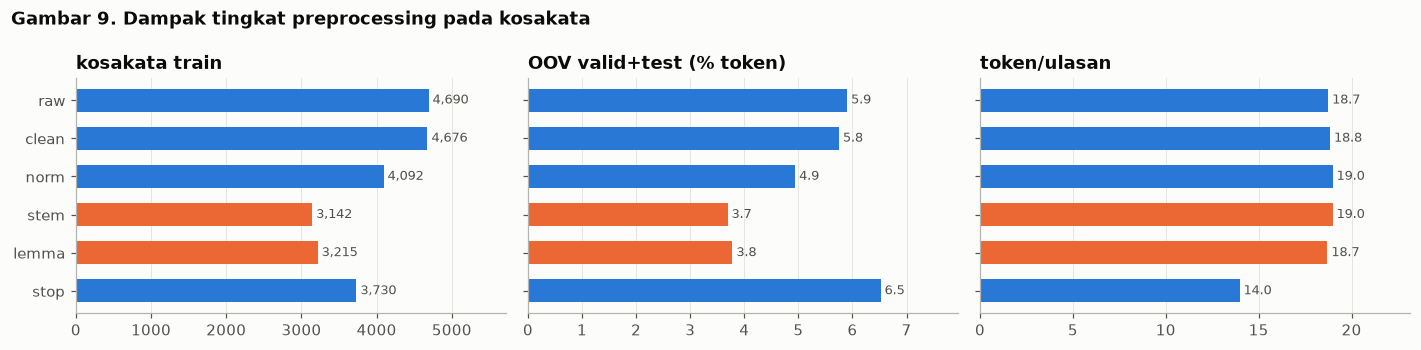

In [35]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
order = LEVELS[::-1]
for ax, col in zip(axes, ["kosakata train", "OOV valid+test (% token)", "token/ulasan"]):
    ax.barh(order, stats.loc[order, col], color=[C_NEG if l in ("stem", "lemma") else C_POS for l in order], height=0.6)
    for i, v in enumerate(stats.loc[order, col]):
        ax.text(v, i, f" {v:,.1f}" if v < 100 else f" {v:,.0f}", va="center", fontsize=8.5, color=INK_2)
    ax.set_title(col)
    ax.set_xlim(0, stats[col].max() * 1.22)
    ax.grid(axis="y", visible=False)
fig.suptitle("Gambar 9. Dampak tingkat preprocessing pada kosakata", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_fig(fig, "09_dampak_preprocessing")
plt.show()

Normalisasi menurunkan kosakata train dari 4.690 menjadi 4.092 tipe dan OOV dari 5,90% menjadi 4,94%. Stemming dan lemmatisasi menurunkan kosakata lebih jauh (3.142 dan 3.215 tipe), sedangkan penghapusan stopword memperpendek ulasan dari sekitar 19 menjadi 14 token.

### 7.5 Kesalahan stemmer dan lemmatizer pada domain hotel

Stemmer dan lemmatizer dirancang untuk teks baku, sehingga dapat menghasilkan kesalahan yang mengubah makna kata kunci aspek dan kata sentimen.

In [36]:
probe = ["sarapan", "sarapannya", "pelayanan", "pelayan", "perbaikan", "pendingin", "lemot", "menarik",
         "kebersihan", "kenyamanan", "mengecewakan", "berisik", "wifinya", "ngecewain", "bersihin", "keramahan"]
lem = P.lemmatize_all(probe)
tab = pd.DataFrame({"kata": probe, "frekuensi di HoASA": [cnt[w] for w in probe],
                    "stem Sastrawi": [P.stem_word(w) for w in probe], "lemma Stanza": lem}).set_index("kata")
tab

,frekuensi di HoASA,stem Sastrawi,lemma Stanza
kata,,,
sarapan,112,sarap,sarap
sarapannya,24,sarap,sarap
pelayanan,297,layan,layan
pelayan,15,layan,layan
perbaikan,24,baik,baik
pendingin,5,dingin,dingin
lemot,25,lot,lemot
menarik,4,tarik,menarik
kebersihan,180,bersih,bersih


Beberapa kesalahan berdampak langsung pada ABSA. Kedua alat mengubah *sarapan* menjadi *sarap*, padahal *sarapan* adalah kata kunci utama aspek `sunrise_meal`. *Perbaikan* menjadi *baik*, sehingga keluhan berubah menjadi kata pujian, dan *pendingin* menjadi *dingin*. Sastrawi mengubah *lemot*, kata keluhan wifi yang paling khas, menjadi *lot*, sedangkan Stanza mengubah *bersihin* menjadi *sihin*. Sastrawi juga tidak mengubah kata informal (*ngecewain*) dan bentuk ber-klitik (*wifinya*), sehingga stemming hanya bekerja sebagian pada teks informal.

### 7.6 Stopword dan negasi

Daftar stopword Sastrawi dibandingkan dengan daftar terkurasi yang mempertahankan negasi, kata intensitas, kata kontras, dan kata opini.

In [37]:
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

sastrawi_sw = set(StopWordRemoverFactory().get_stop_words())
crit = sorted(sastrawi_sw & (P.KEEP_WORDS | {"tak"}))
print(f"Daftar stopword Sastrawi ({len(sastrawi_sw)} kata) memuat kata penentu sentimen/aspek:\n  {crit}")
norm_tok = ALLD.text_norm.str.split()
neg_rev = norm_tok.map(lambda ws: any(w in {"tidak", "kurang", "belum", "bukan"} for w in ws))
print(f"\nUlasan yang mengandung negasi/kurang setelah normalisasi: {neg_rev.mean():.1%}")
removed_std = np.mean([w in sastrawi_sw for ws in norm_tok for w in ws])
removed_ours = np.mean([w in P.stopwords() for ws in norm_tok for w in ws])
print(f"Token yang dibuang: daftar Sastrawi asli {removed_std:.1%} | daftar kami (negasi dsb. dipertahankan) {removed_ours:.1%}")
ex = "kamar kurang bersih tapi pelayanan sangat baik tidak ada masalah"
print("\nContoh  :", ex)
print("Sastrawi:", " ".join(w for w in ex.split() if w not in sastrawi_sw))
print("Kami    :", P.remove_stop(ex))

Daftar stopword Sastrawi (809 kata) memuat kata penentu sentimen/aspek:
  ['ada', 'agak', 'baik', 'baru', 'belum', 'besar', 'bisa', 'bukan', 'cukup', 'dekat', 'enak', 'harus', 'jangan', 'jauh', 'kecil', 'keluar', 'kurang', 'lama', 'lebih', 'masalah', 'masih', 'meskipun', 'namun', 'padahal', 'paling', 'sangat', 'sekali', 'sudah', 'tak', 'tanpa', 'tapi', 'terlalu', 'tetapi', 'tidak', 'walaupun']

Ulasan yang mengandung negasi/kurang setelah normalisasi: 74.1%
Token yang dibuang: daftar Sastrawi asli 42.5% | daftar kami (negasi dsb. dipertahankan) 26.4%

Contoh  : kamar kurang bersih tapi pelayanan sangat baik tidak ada masalah
Sastrawi: kamar bersih pelayanan
Kami    : kamar kurang bersih tapi pelayanan sangat baik tidak ada masalah


Daftar Sastrawi (809 kata) memuat *tidak*, *kurang*, *tapi*, *sangat*, dan *baik*. Dengan daftar tersebut, kalimat "kamar kurang bersih tapi pelayanan sangat baik tidak ada masalah" menjadi "kamar bersih pelayanan", sehingga sentimen kebersihan terbalik. Setelah normalisasi, 74,1% ulasan mengandung *tidak*, *kurang*, *belum*, atau *bukan*. Daftar terkurasi (`KEEP_WORDS`) mempertahankan kata-kata tersebut.

### 7.7 Tokenisasi subword untuk transformer

Untuk empat tokenizer diukur *fertility*, yaitu rata-rata subword per kata (makin rendah, makin sesuai kosakata tokenizer dengan bahasa teks), proporsi token `[UNK]`, dan panjang ulasan dalam subword.

In [38]:
from transformers import AutoTokenizer

TOKENIZERS = {"IndoBERT-base-p1": "indobenchmark/indobert-base-p1", "IndoBERTweet": "indolem/indobertweet-base-uncased",
              "XLM-R": "FacebookAI/xlm-roberta-base", "mBERT": "google-bert/bert-base-multilingual-uncased"}
tr_texts = ALLD[is_tr]
fert = []
for name, path in TOKENIZERS.items():
    tok = AutoTokenizer.from_pretrained(path)
    for c in ["raw", "clean", "norm", "stem"]:
        texts = tr_texts[f"text_{c}"].tolist()
        enc = tok(texts, add_special_tokens=False)["input_ids"]
        # fertility dihitung atas kata saja (tanda baca dibuang) agar tingkat yang membuang tanda baca tidak diuntungkan
        wl = [" ".join(re.findall(r"[a-z0-9]+", t.lower())) for t in texts]
        n_sub = sum(map(len, tok(wl, add_special_tokens=False)["input_ids"]))
        n_word = sum(len(t.split()) for t in wl)
        unk = sum(i == tok.unk_token_id for ids in enc for i in ids)
        lens = np.array([len(e) + 2 for e in enc])
        fert.append({"tokenizer": name, "tingkat": c, "fertility": n_sub / n_word, "% [UNK]": 100 * unk / sum(map(len, enc)),
                     "p95 panjang": np.percentile(lens, 95), "% > 128 subword": 100 * (lens > 128).mean(),
                     "% > 256 subword": 100 * (lens > 256).mean()})
fert = pd.DataFrame(fert).round(3)
fert.pivot(index="tokenizer", columns="tingkat", values="fertility")[["raw", "clean", "norm", "stem"]]

tingkat,raw,clean,norm,stem
tokenizer,,,,
IndoBERT-base-p1,1.107,1.101,1.086,1.081
IndoBERTweet,1.116,1.112,1.109,1.089
XLM-R,1.280,1.274,1.225,1.172
mBERT,1.526,1.521,1.476,1.379


In [39]:
display(fert[fert.tingkat.isin(["raw", "clean"])].set_index(["tokenizer", "tingkat"])[["% [UNK]", "p95 panjang", "% > 128 subword", "% > 256 subword"]])
tok = AutoTokenizer.from_pretrained(TOKENIZERS["IndoBERT-base-p1"])
s = "kamarnya bersih 😊 tapi wifinya lemottt bgt"
print("raw  :", tok.tokenize(s))
print("clean:", tok.tokenize(P.clean(s)))

% [UNK]  p95 panjang  % > 128 subword  % > 256 subword
tokenizer        tingkat                                                        
IndoBERT-base-p1 raw        0.086        68.00            0.221              0.0
                 clean      0.004        67.05            0.221              0.0
IndoBERTweet     raw        0.076        68.00            0.177              0.0
                 clean      0.000        68.00            0.177              0.0
XLM-R            raw        0.000        77.00            0.221              0.0
                 clean      0.000        76.00            0.221              0.0
mBERT            raw        0.060        89.00            0.310              0.0
                 clean      0.000        88.00            0.310              0.0

raw  : ['kamarnya', 'bersih', '[UNK]', 'tapi', 'wifi', '##nya', 'lemot', '##tt', 'bgt']
clean: ['kamarnya', 'bersih', 'wajah', 'tersenyum', 'dengan', 'mata', 'bahagia', 'tapi', 'wifi', '##nya', 'lemot', 'bgt']


IndoBERT-base-p1: median 20 | p95 67 | p99 84 | maks 172 | > 64: 5.9% | > 128: 6 ulasan (0.2%)


XLM-R           : median 23 | p95 76 | p99 98 | maks 191 | > 64: 8.6% | > 128: 8 ulasan (0.3%)


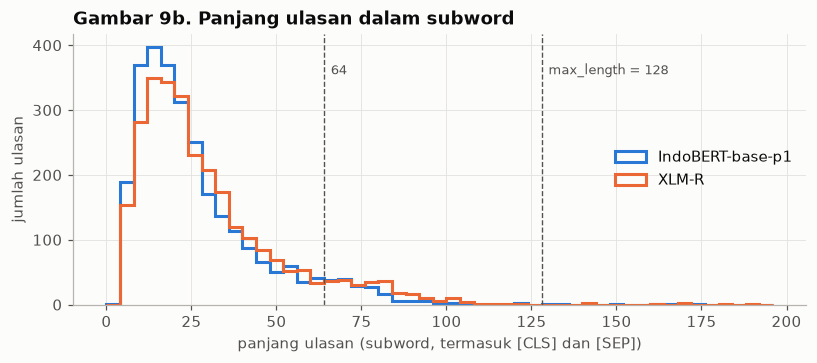

In [40]:
# Panjang input dalam subword (text_clean, semua split) -> dasar pemilihan max_length
fig, ax = plt.subplots(figsize=(8.6, 3.2))
for name, c in [("IndoBERT-base-p1", C_POS), ("XLM-R", C_NEG)]:
    t = AutoTokenizer.from_pretrained(TOKENIZERS[name])
    L = np.array([len(e) for e in t(ALLD.text_clean.tolist())["input_ids"]])
    ax.hist(L, bins=np.arange(0, 200, 4), histtype="step", lw=2, color=c, label=name)
    print(f"{name:16s}: median {np.median(L):.0f} | p95 {np.percentile(L, 95):.0f} | p99 {np.percentile(L, 99):.0f} | "
          f"maks {L.max()} | > 64: {(L > 64).mean():.1%} | > 128: {(L > 128).sum()} ulasan ({(L > 128).mean():.1%})")
for x, lab in [(64, "64"), (128, "max_length = 128")]:
    ax.axvline(x, color=INK_2, lw=0.9, ls="--")
    ax.text(x + 2, ax.get_ylim()[1] * 0.85, lab, fontsize=8.5, color=INK_2)
ax.set_xlabel("panjang ulasan (subword, termasuk [CLS] dan [SEP])")
ax.set_ylabel("jumlah ulasan")
ax.set_title("Gambar 9b. Panjang ulasan dalam subword")
ax.legend(loc="center right")
save_fig(fig, "09b_panjang_subword")
plt.show()

IndoBERT memiliki fertility terendah (sekitar 1,1 subword per kata), diikuti IndoBERTweet, XLM-R (sekitar 1,27), dan mBERT (sekitar 1,52). Urutan ini sejalan dengan urutan performa pada makalah IndoNLU untuk model berukuran sama. Pada teks `raw`, emoji menjadi `[UNK]` pada IndoBERT dan mBERT, dan tingkat `clean` menghilangkan hampir seluruhnya.

Panjang maksimum input ditetapkan **128 subword** (Gambar 9b). Batas ini hanya memotong 6 ulasan pada IndoBERT dan 8 ulasan pada XLM-R (0,2–0,3%), sedangkan batas 64 akan memotong 5,9–8,6% ulasan, padahal ulasan panjang membahas paling banyak aspek. Di atas 128, biaya *self-attention* naik secara kuadratik tanpa tambahan informasi yang berarti.

### 7.8 Eksperimen preprocessing

Pengaruh setiap tingkat diuji dengan 5-fold cross-validation pada gabungan train dan valid (2.545 ulasan); test tidak dipakai. Fold dibentuk dengan stratifikasi multi-label atas pasangan aspek dan polaritas, dan fold yang sama dipakai untuk semua tingkat dan semua model sehingga perbandingannya berpasangan. Model yang diuji adalah TF-IDF dengan Logistic Regression (n-gram kata, serta kata ditambah karakter), BiLSTM dengan FastText, dan IndoBERT-base. Model neural dilatih melalui `scripts/prep_ablation.py`, dan hasilnya dimuat di sini.

In [41]:
from iterstrat.ml_stratifiers import MultilabelStratifiedKFold

CV = ALLD[ALLD.split.isin(["train", "valid"])].reset_index(drop=True)
Ycv = to_ids(CV)
strat = np.concatenate([(Ycv == k).astype(int) for k in (LABEL2ID["neg"], LABEL2ID["pos"])], axis=1)
CV["fold"] = -1
for f, (_, te) in enumerate(MultilabelStratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(CV, strat)):
    CV.loc[te, "fold"] = f
print("Ukuran fold:", CV.fold.value_counts().sort_index().tolist())
print("Sel pos per fold:", [int((Ycv[CV.fold == f] == 2).sum()) for f in range(5)])

Ukuran fold: [511, 509, 508, 510, 507]
Sel pos per fold: [216, 216, 213, 217, 213]


In [42]:
from scipy.sparse import hstack
from sklearn.linear_model import LogisticRegression
from hoasa.metrics import metrics as score


def tfidf_cv(level, use_char):
    res = []
    for f in range(5):
        tr, te = CV.fold != f, CV.fold == f
        X_tr_txt, X_te_txt = CV.loc[tr, f"text_{level}"].str.lower(), CV.loc[te, f"text_{level}"].str.lower()
        vw = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, token_pattern=r"(?u)\b\w+\b")
        Xtr, Xte = vw.fit_transform(X_tr_txt), vw.transform(X_te_txt)
        if use_char:
            vc = TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True)
            Xtr, Xte = hstack([Xtr, vc.fit_transform(X_tr_txt)]).tocsr(), hstack([Xte, vc.transform(X_te_txt)]).tocsr()
        pred = np.zeros((te.sum(), len(ASPECTS)), dtype=int)
        for j in range(len(ASPECTS)):
            clf = LogisticRegression(C=10, class_weight="balanced", max_iter=3000)
            pred[:, j] = clf.fit(Xtr, Ycv[tr, j]).predict(Xte)
        res.append({"fold": f, **score(Ycv[te], pred)})
    return res


rows = []
for model, use_char in [("TF-IDF kata", False), ("TF-IDF kata+karakter", True)]:
    for lvl in LEVELS:
        rows += [{"model": model, "tingkat": lvl, **r} for r in tfidf_cv(lvl, use_char)]
cv_tfidf = pd.DataFrame(rows)
cv_tfidf.groupby(["model", "tingkat"], sort=False)[["f1_indonlu", "f1_pair"]].mean().unstack(0).round(4)

f1_indonlu                          f1_pair                     
model   TF-IDF kata TF-IDF kata+karakter TF-IDF kata TF-IDF kata+karakter
tingkat                                                                  
raw          0.8220               0.8336      0.7995               0.8164
clean        0.8237               0.8344      0.8003               0.8159
norm         0.8252               0.8372      0.8049               0.8212
stem         0.8242               0.8308      0.8093               0.8177
lemma        0.8325               0.8366      0.8156               0.8231
stop         0.8340               0.8396      0.8159               0.8273

Run neural tersedia: {('BiLSTM + FastText', 'clean'): 5, ('BiLSTM + FastText', 'lemma'): 5, ('BiLSTM + FastText', 'norm'): 5, ('BiLSTM + FastText', 'raw'): 5, ('BiLSTM + FastText', 'stem'): 5, ('BiLSTM + FastText', 'stop'): 5, ('IndoBERT-base', 'clean'): 5, ('IndoBERT-base', 'lemma'): 5, ('IndoBERT-base', 'norm'): 5, ('IndoBERT-base', 'raw'): 5, ('IndoBERT-base', 'stem'): 5, ('IndoBERT-base', 'stop'): 5}


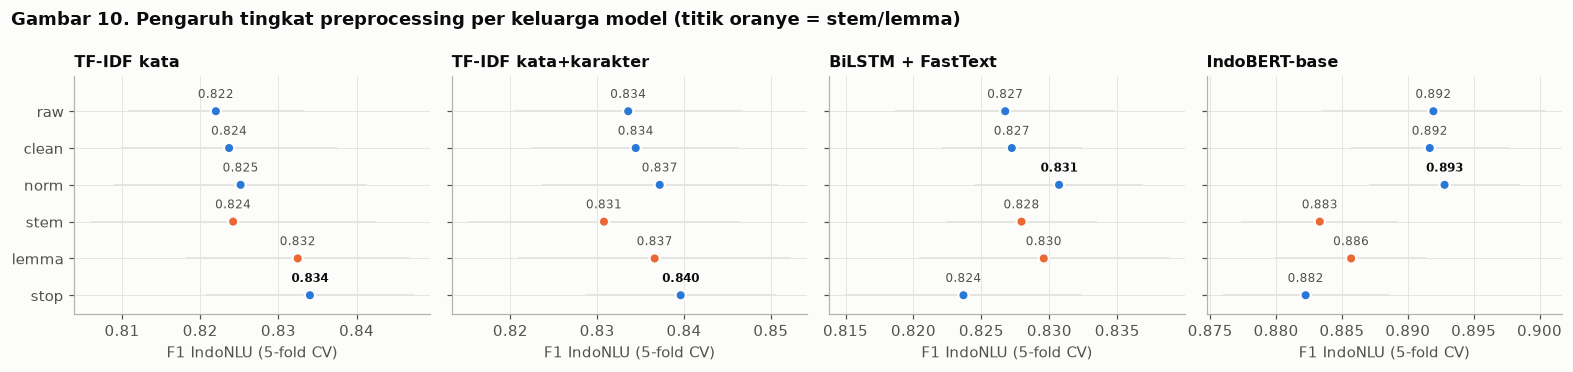

In [43]:
import json

ABL = ROOT / "outputs" / "prep_ablation.jsonl"
cv_nn = pd.DataFrame([json.loads(l) for l in ABL.read_text().splitlines()]) if ABL.exists() else pd.DataFrame()
cv_all = pd.concat([cv_tfidf, cv_nn], ignore_index=True)
print("Run neural tersedia:", cv_nn.groupby(["model", "tingkat"]).size().to_dict() if len(cv_nn) else "belum ada")

MODELS = [m for m in ["TF-IDF kata", "TF-IDF kata+karakter", "BiLSTM + FastText", "IndoBERT-base"] if m in set(cv_all.model)]
fig, axes = plt.subplots(1, len(MODELS), figsize=(3.6 * len(MODELS), 3.4), sharey=True)
axes = np.atleast_1d(axes)
for ax, m in zip(axes, MODELS):
    sub = cv_all[cv_all.model == m]
    g = sub.groupby("tingkat").f1_indonlu
    mean, sd = g.mean().reindex(LEVELS), g.std().reindex(LEVELS)
    best = mean.idxmax()
    ax.errorbar(mean.values, range(len(LEVELS)), xerr=sd.values, fmt="none", ecolor=GRID, elinewidth=1.2, capsize=0)
    ax.scatter(mean.values, range(len(LEVELS)), s=46, zorder=3,
               color=[C_NEG if l in ("stem", "lemma") else C_POS for l in LEVELS], edgecolor=SURFACE, linewidth=1.5)
    for i, l in enumerate(LEVELS):
        ax.text(mean[l], i - 0.28, f"{mean[l]:.3f}", ha="center", va="bottom", fontsize=8, color=INK if l == best else INK_2,
                fontweight="bold" if l == best else "normal")
    ax.set_yticks(range(len(LEVELS)), LEVELS)
    ax.set_ylim(len(LEVELS) - 0.5, -0.95)         # raw di atas; ruang untuk label titik teratas
    ax.set_title(m, fontsize=10.5)
    ax.set_xlabel("F1 IndoNLU (5-fold CV)")
fig.suptitle("Gambar 10. Pengaruh tingkat preprocessing per keluarga model (titik oranye = stem/lemma)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save_fig(fig, "10_eksperimen_preprocessing")
plt.show()

In [44]:
from scipy.stats import ttest_rel

def paired_vs(model, ref):
    sub = cv_all[cv_all.model == model].pivot(index="fold", columns="tingkat", values="f1_indonlu")
    out = {}
    for l in LEVELS:
        if l == ref or l not in sub:
            continue
        d = sub[l] - sub[ref]
        out[l] = {"selisih rata-rata (poin)": round(100 * d.mean(), 2), "fold lebih baik": f"{(d > 0).sum()}/5",
                  "p (uji-t berpasangan)": round(ttest_rel(sub[l], sub[ref]).pvalue, 3)}
    return pd.DataFrame(out).T


for m in MODELS:
    ref = "norm" if m.startswith("TF-IDF") or m.startswith("BiLSTM") else "clean"
    print(f"\n{m}: dibandingkan dengan tingkat '{ref}'")
    display(paired_vs(m, ref))


TF-IDF kata: dibandingkan dengan tingkat 'norm'


,selisih rata-rata (poin),fold lebih baik,p (uji-t berpasangan)
raw,-0.32,2/5,0.389
clean,-0.15,2/5,0.683
stem,-0.1,1/5,0.729
lemma,0.73,5/5,0.021
stop,0.89,5/5,0.012



TF-IDF kata+karakter: dibandingkan dengan tingkat 'norm'


,selisih rata-rata (poin),fold lebih baik,p (uji-t berpasangan)
raw,-0.36,1/5,0.174
clean,-0.28,2/5,0.444
stem,-0.64,1/5,0.179
lemma,-0.06,2/5,0.763
stop,0.24,3/5,0.668



BiLSTM + FastText: dibandingkan dengan tingkat 'norm'


,selisih rata-rata (poin),fold lebih baik,p (uji-t berpasangan)
raw,-0.4,1/5,0.404
clean,-0.35,2/5,0.431
stem,-0.28,1/5,0.412
lemma,-0.11,2/5,0.74
stop,-0.7,1/5,0.126



IndoBERT-base: dibandingkan dengan tingkat 'clean'


,selisih rata-rata (poin),fold lebih baik,p (uji-t berpasangan)
raw,0.03,2/5,0.831
norm,0.11,2/5,0.596
stem,-0.83,0/5,0.006
lemma,-0.6,1/5,0.027
stop,-0.94,0/5,0.054


Angka berikut adalah F1 IndoNLU rata-rata lima fold dengan uji-t berpasangan. Dengan hanya lima fold, p < 0,05 baru tercapai bila efeknya konsisten pada hampir semua fold.

TF-IDF kata adalah satu-satunya model yang terbantu oleh pengurangan kosakata. Lemmatisasi menaikkan F1 sebesar 0,73 poin (p = 0,021) dan penghapusan stopword terkurasi sebesar 0,89 poin (p = 0,012), sedangkan stemming tidak membantu (−0,10 poin). Setelah n-gram karakter ditambahkan, tidak ada lagi selisih yang signifikan. Pada BiLSTM dengan FastText, semua tingkat berada dalam 0,7 poin dari `norm` dan tidak ada yang signifikan (p ≥ 0,12), karena embedding FastText sudah dibentuk dari n-gram karakter.

Pada IndoBERT-base, tingkat `raw`, `clean`, dan `norm` setara (selisih paling besar 0,11 poin). Stemming menurunkan F1 sebesar 0,83 poin (0/5 fold, p = 0,006) dan lemmatisasi sebesar 0,60 poin (1/5 fold, p = 0,027); keduanya signifikan. Penghapusan stopword menurunkan F1 sebesar 0,94 poin dan lebih buruk pada kelima fold, tetapi belum signifikan (p = 0,054). Transformer dilatih pada teks alami, sehingga membuang imbuhan dan kata fungsi membuat input berbeda dari teks pretraining.

Selisih antar keluarga model, sekitar 6 poin antara IndoBERT dan BiLSTM, jauh lebih besar daripada efek preprocessing mana pun (kurang dari 1 poin).

### 7.9 Representasi input untuk setiap jenis model

Satu ulasan berikut ditampilkan dalam bentuk yang diterima oleh setiap jenis model.

In [45]:
i = ALLD.index[ALLD.review.str.contains("sarapan") & (ALLD.review.str.split().str.len().between(8, 14))][0]
row = ALLD.loc[i]
print("Ulasan asli:", row.review)
print("Label      :", to_tuples(row), "\n")

# (1) TF-IDF: vektor jarang
vw = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, token_pattern=r"(?u)\b\w+\b").fit(CV.text_norm)
v = vw.transform([row.text_norm])
feats = vw.get_feature_names_out()
nz = sorted(zip(v.indices, v.data), key=lambda x: -x[1])[:8]
print(f"(1) TF-IDF ({len(feats):,} dimensi, {v.nnz} bukan nol):", {feats[k]: round(float(w), 3) for k, w in nz})

# (2) BiLSTM: urutan indeks kata -> embedding 300 dimensi
vocab = {w: k + 2 for k, (w, _) in enumerate(Counter(w for t in CV.text_norm for w in t.split()).most_common())}
seq = [vocab.get(w, 1) for w in row.text_norm.split()]
print(f"\n(2) BiLSTM: token {row.text_norm.split()}\n    indeks  {seq}  (0 = padding, 1 = OOV) -> tensor ({len(seq)}, 300)")

# (3) IndoBERT: subword, input_ids, attention_mask
enc = tok(row.text_clean, max_length=128, truncation=True)
print(f"\n(3) IndoBERT subword  : {tok.convert_ids_to_tokens(enc['input_ids'])}")
print(f"    input_ids         : {enc['input_ids']}")
print(f"    attention_mask    : {enc['attention_mask']}")

# (4) Pasangan kalimat (auxiliary sentence, Sun et al., 2019): 10 contoh per ulasan
pair = tok(row.text_clean, ASPECT_TEXT["sunrise_meal"])
print(f"\n(4) Pasangan kalimat (aspek sunrise_meal): {tok.decode(pair['input_ids'])}")
print(f"    token_type_ids    : {pair['token_type_ids']}  -> label: {row['sunrise_meal']}")

# (5) LLM: prompt instruksi
print("\n(5) Prompt LLM:\nUlasan hotel: " + row.review + "\nTentukan sentimen (negatif/netral/positif) untuk aspek: "
      + ", ".join(ASPECT_TEXT.values()) + ".\nJawaban:")

Ulasan asli: Kamarnya terlalu sederhana. Makan sarapan paginya tidak enak. Pelayanan kurang. Tempat makan kurang nyaman.
Label      : [('service', 'neg'), ('sunrise_meal', 'neg')] 

(1) TF-IDF (6,902 dimensi, 20 bukan nol): {'makan': 0.345, 'enak pelayanan': 0.3, 'kamarnya terlalu': 0.3, 'kurang tempat': 0.3, 'terlalu sederhana': 0.3, 'paginya': 0.289, 'sederhana': 0.262, 'tempat makan': 0.233}

(2) BiLSTM: token ['kamarnya', 'terlalu', 'sederhana', 'makan', 'sarapan', 'paginya', 'tidak', 'enak', 'pelayanan', 'kurang', 'tempat', 'makan', 'kurang', 'nyaman']
    indeks  [45, 116, 710, 189, 90, 1179, 2, 88, 33, 7, 42, 189, 7, 19]  (0 = padding, 1 = OOV) -> tensor (14, 300)

(3) IndoBERT subword  : ['[CLS]', 'kamarnya', 'terlalu', 'sederhana', '.', 'makan', 'sarapan', 'paginya', 'tidak', 'enak', '.', 'pelayanan', 'kurang', '.', 'tempat', 'makan', 'kurang', 'nyaman', '.', '[SEP]']
    input_ids         : [2, 13455, 1386, 2364, 30470, 521, 6499, 24028, 119, 3107, 30470, 1753, 1057, 30470, 5

### 7.10 Rekomendasi preprocessing

Kebutuhan stemming dan lemmatisasi bergantung pada model. Untuk model neural dan transformer pada proyek ini, keduanya tidak diperlukan.

| Keluarga model | Input | Stemming | Lemmatisasi | Stopword | Dasar |
|---|---|---|---|---|---|
| TF-IDF kata | `text_stop` atau `text_lemma` | tidak | opsional (+0,7) | daftar terkurasi (+0,9) | 7.8 |
| TF-IDF kata + karakter | `text_norm` | tidak | tidak | tidak | 7.8 |
| BiLSTM/CNN + FastText | `text_norm` | tidak | tidak | tidak | 7.4, 7.8 |
| Transformer | `text_clean` | tidak | tidak | tidak | 7.7, 7.8 |

Untuk transformer, `clean` dipilih daripada `norm` karena hasilnya setara dan tidak bergantung pada kamus. Daftar stopword generik tidak dipakai pada model mana pun, karena membuang negasi yang muncul pada 74,1% ulasan. Panjang maksimum input adalah 128 subword, termasuk untuk formulasi pasangan kalimat pada notebook 3.

## 8. Menyimpan Data Hasil Olahan

Data hasil olahan disimpan ke `data/processed/` beserta pembagian fold CV dan berkas `meta.json`, untuk dipakai oleh skrip pelatihan dan notebook berikutnya.

In [46]:
keep = (["review"] + [f"text_{c}" for c in LEVELS if c != "raw"] + ASPECTS + [f"{a}_orig" for a in ASPECTS] + ["suspect"])
for s in SPLITS:
    d = ALLD[ALLD.split == s][keep]
    d.to_csv(PROC_DIR / f"{s}.csv", index=False)
    print(f"{s:5s}: {len(d):5,d} ulasan -> {PROC_DIR / f'{s}.csv'}")
CV[["review", "fold"]].to_csv(PROC_DIR / "cv_folds.csv", index=False)

meta = {
    "source": "IndoNLU hoasa_absa-airy (github.com/IndoNLP/indonlu)",
    "aspects": ASPECTS, "aspect_text": ASPECT_TEXT,
    "classes_train": ["neg", "neut", "pos", "neg_pos"], "classes_eval": ["neg", "neut", "pos"],
    "neg_pos_handling": "latih 4 kelas (kolom <aspek>_orig); saat prediksi p(neg) += p(neg_pos)",
    "text_columns": {c: f"text_{c}" for c in LEVELS if c != "raw"},
    "removed_train": {"duplicates": int(n0 - n1), "leaked_to_valid_test": int(len(leaked))},
    "max_length": {"single": 128, "pair": 128},
    "cv": {"n_splits": 5, "seed": SEED, "file": "cv_folds.csv"},
}
(PROC_DIR / "meta.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False), encoding="utf-8")
print("meta.json tersimpan")

train: 2,260 ulasan -> /home/athal/Documents/projects/dl-assignment/data/processed/train.csv
valid:   285 ulasan -> /home/athal/Documents/projects/dl-assignment/data/processed/valid.csv
test :   286 ulasan -> /home/athal/Documents/projects/dl-assignment/data/processed/test.csv
meta.json tersimpan


## 9. Kesimpulan

HoASA berisi 2.854 ulasan hotel yang pendek (median 14 kata) dengan sepuluh aspek. Label `neut` berarti aspek tidak dibahas, dan distribusinya sangat timpang dengan 80,6% sel `neut`, 15,3% `neg`, dan 4,2% `pos`. Definisi aspek lebih luas daripada namanya, terutama `linen`, dan terdapat indikasi label noise. Dari train dihapus 21 duplikat dan 2 ulasan yang bocor, model dilatih dengan empat kelas yang digabung menjadi tiga saat prediksi, dan valid serta test tidak diubah.

Kebutuhan preprocessing bergantung pada model. Transformer cukup memakai pembersihan ringan (`clean`); pada IndoBERT, stemming dan lemmatisasi menurunkan F1 secara signifikan, sedangkan penghapusan stopword menurunkan F1 pada kelima fold walaupun belum signifikan (p = 0,054). Temuan EDA mengarahkan pemodelan pada transformer dengan panjang maksimum 128 subword, pembanding berbasis frasa pendek karena 89% opini berada dalam 5 kata dari aspeknya, dan model kontekstual untuk opini yang jauh serta aspek implisit. Kaitan lengkapnya terdapat pada bagian 5.10.